# Reglas de Asociación y Sistema de Recomendación de Películas
## Taller 2 · Aprendizaje no supervisado · Grupo 6

**Docente:** Danilo Gómez Correa

**Integrantes:**
- Lucas Hermosilla Díaz
- Rodolfo Hidalgo Memmel
- Ariel Linero Torres

**Fecha:** 19-10-2026

**Base de datos:** MovieLens 1M (GroupLens, Universidad de Minnesota): 1.000.209 evaluaciones de 6.040 usuarios sobre 3.883 películas.

**Contenido**
1. Problema y base de datos.
2. Limpieza y transacciones.
3. Exploración.
4. Itemsets y reglas.
5. Fisher, redundantes y consulta dirigida.
6. Recomendador.
7. Evaluación offline.
8. Hallazgos y recomendaciones.
9. Exportación de CSV para el dashboard.

**Librerías:** `pandas`, `mlxtend` (Apriori / FP-Growth), `scipy` y `statsmodels` (pruebas estadísticas),
`matplotlib` y `networkx` (gráficos), `pyvis` y `plotly` (gráficos interactivos).

## 0. Preparación del entorno

In [1]:
# mlxtend: Apriori y FP-Growth (versión reciente) | pyvis: grafos interactivos
# Se fijan pandas y numpy en versiones compatibles con Colab para evitar conflictos.
!pip install -q -U mlxtend pyvis "pandas<3.0" "numpy<2.3"
# ¡IMPORTANTE!: Después de que termine la instalación, reinicia el entorno de ejecución (Runtime -> Restart session)

In [2]:
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.express as px
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Configuración de visualización
pd.set_option("display.float_format", "{:.3f}".format)   # 3 decimales en las tablas
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 110

# Paleta de colores del curso
AZUL = "#0b1f45"
GRIS = "#52607a"
ROJO = "#c0392b"

# Semilla fija para que todo sea reproducible (partición 80/20 y leave-one-out)
SEMILLA = 2026

# Filter Warnings
import warnings
warnings.filterwarnings("ignore")

### Funciones auxiliares

`mlxtend` guarda los antecedentes y consecuentes como `frozenset`, que se leen mal en una tabla. Esta función deja las reglas en un formato legible: `{Matrix, The (1999)} ⇒ {Terminator 2: Judgment Day (1991)}`.

In [3]:
def texto_itemset(itemset):
    # Convierte un frozenset en texto ordenado, por ejemplo: {Alien (1979), Aliens (1986)}
    return "{" + ", ".join(sorted(itemset)) + "}"


def tabla_reglas(reglas):
    # Devuelve una tabla limpia con las columnas que usamos en clase, ordenada por lift
    tabla = pd.DataFrame({
        "regla": reglas["antecedents"].apply(texto_itemset) + " ⇒ " + reglas["consequents"].apply(texto_itemset),
        "soporte": reglas["support"],
        "confianza": reglas["confidence"],
        "lift": reglas["lift"],
        "leverage": reglas["leverage"],
        "conviccion": reglas["conviction"],
    })
    return tabla.sort_values("lift", ascending=False).reset_index(drop=True)

## 1. Problema y base de datos

**Base:** MovieLens 1M (GroupLens Research, Universidad de Minnesota): **1.000.209 evaluaciones** de **6.040 usuarios** sobre **3.883 películas**, con notas de 1 a 5 estrellas, recopiladas en el año 2000.

| | |
|---|---|
| **Fuente** | https://grouplens.org/datasets/movielens/1m/ |
| **Licencia** | Uso libre para investigación y docencia, citando la fuente. No permite redistribuir los datos ni uso comercial, por lo que el notebook los descarga directamente desde GroupLens. |
| **Cita** | Harper, F. M. y Konstan, J. A. (2015). The MovieLens Datasets: History and Context. *ACM Transactions on Interactive Intelligent Systems*, 5(4), 19. |
| **Transacción** | Un **usuario**: el conjunto de películas que le gustaron. |
| **Ítem** | Una **película** evaluada con **nota ≥ 4**. |

**¿Por qué nota ≥ 4?** Una nota baja indica que la película *no* le gustó al usuario. Si la incluyéramos, una regla como {A} ⇒ {B} podría significar "a quien le disgustó A también le disgustó B", lo que no sirve para recomendar. Con nota ≥ 4, cada transacción representa los gustos del usuario.

**Problema y uso del recomendador:** una plataforma de streaming quiere sugerir qué ver a continuación. Las reglas del tipo "a quienes les gustó *Matrix* también les gustó *Terminator 2*" permiten armar recomendaciones del estilo **"porque te gustó…"**, aumentar el tiempo de visualización y ayudar a descubrir títulos del catálogo que el usuario no conoce.

### 1.1 Carga de datos

In [4]:
URL = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"

# Descargamos el zip (~6 MB) desde GroupLens y lo descomprimimos
urllib.request.urlretrieve(URL, "ml-1m.zip")
with zipfile.ZipFile("ml-1m.zip") as archivo:
    archivo.extractall()

# Los archivos usan "::" como separador (dos caracteres), por eso se necesita engine="python".
# movies.dat trae títulos con tildes y caracteres especiales en codificación latin-1.
ratings = pd.read_csv("ml-1m/ratings.dat", sep="::", engine="python",
                      names=["usuario", "pelicula_id", "nota", "timestamp"])

peliculas = pd.read_csv("ml-1m/movies.dat", sep="::", engine="python",
                        names=["pelicula_id", "titulo", "generos"], encoding="latin-1")

usuarios = pd.read_csv("ml-1m/users.dat", sep="::", engine="python",
                       names=["usuario", "genero", "edad", "ocupacion", "codigo_postal"])

print(f"Evaluaciones: {len(ratings):,}")
print(f"Películas:    {len(peliculas):,}")
print(f"Usuarios:     {len(usuarios):,}")
display(ratings.head())
display(peliculas.head())
display(usuarios.head())

Evaluaciones: 1,000,209
Películas:    3,883
Usuarios:     6,040


,usuario,pelicula_id,nota,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


,pelicula_id,titulo,generos
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


,usuario,genero,edad,ocupacion,codigo_postal
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


## 2. Limpieza y transacciones

La base tiene tres archivos, cada uno con un rol distinto:

| Archivo | Contenido | Rol en el análisis |
|---|---|---|
| `ratings.dat` | Una fila por evaluación: usuario, película, nota (1 a 5) y fecha | **Forma las transacciones** |
| `movies.dat` | Código, título y géneros de cada película | **Traduce** los códigos a títulos legibles |
| `users.dat` | Género, edad, ocupación y código postal de cada usuario | **Contexto**: no entra en las reglas, pero se verifica su consistencia |

`ratings.dat` viene en **formato largo**: un mismo usuario aparece en muchas filas, una por película evaluada. Para el análisis de canasta necesitamos **una transacción por usuario** con las películas que le gustaron. Los pasos son:

1. Revisar la calidad de los tres archivos: nulos, duplicados, valores fuera de rango y códigos sin correspondencia entre tablas.
2. Quedarnos con las evaluaciones con **nota ≥ 4** y reemplazar el código de cada película por su título (unión de `ratings` con `movies`).
3. Agrupar por usuario con `groupby` para formar las canastas.
4. Construir la matriz binaria usuario × película con `TransactionEncoder`.

### 2.1 Calidad de los datos

In [5]:
# Revisión de calidad de los tres archivos

# 1) Valores nulos
print("Valores nulos por tabla:")
print(f"  ratings:   {ratings.isna().sum().sum()}")
print(f"  peliculas: {peliculas.isna().sum().sum()}")
print(f"  usuarios:  {usuarios.isna().sum().sum()}")

# 2) Duplicados: un usuario no debería evaluar dos veces la misma película,
#    y cada película y usuario debería aparecer una sola vez en su tabla
print("\nDuplicados:")
print(f"  Evaluaciones repetidas (usuario, película): {ratings.duplicated(['usuario', 'pelicula_id']).sum()}")
print(f"  Películas repetidas (código / título):      {peliculas['pelicula_id'].duplicated().sum()} / {peliculas['titulo'].duplicated().sum()}")
print(f"  Usuarios repetidos:                         {usuarios['usuario'].duplicated().sum()}")

# 3) Valores fuera de rango, según los códigos del README
print("\nValores fuera de rango:")
print(f"  Notas fuera de 1–5:           {(~ratings['nota'].between(1, 5)).sum()}")
print(f"  Género distinto de M/F:       {(~usuarios['genero'].isin(['M', 'F'])).sum()}")
print(f"  Edad con código no válido:    {(~usuarios['edad'].isin([1, 18, 25, 35, 45, 50, 56])).sum()}")
print(f"  Ocupación fuera de 0–20:      {(~usuarios['ocupacion'].between(0, 20)).sum()}")

# 4) Códigos sin correspondencia entre tablas
print("\nConsistencia entre tablas:")
print(f"  Evaluaciones de películas que no están en el catálogo: {(~ratings['pelicula_id'].isin(peliculas['pelicula_id'])).sum()}")
print(f"  Evaluaciones de usuarios que no están en users.dat:     {(~ratings['usuario'].isin(usuarios['usuario'])).sum()}")
print(f"  Películas del catálogo sin ninguna evaluación:          {(~peliculas['pelicula_id'].isin(ratings['pelicula_id'])).sum()}")

# 5) Distribución de notas
print("\nDistribución de notas:")
print(ratings["nota"].value_counts().sort_index())

Valores nulos por tabla:
  ratings:   0
  peliculas: 0
  usuarios:  0

Duplicados:
  Evaluaciones repetidas (usuario, película): 0
  Películas repetidas (código / título):      0 / 0
  Usuarios repetidos:                         0

Valores fuera de rango:
  Notas fuera de 1–5:           0
  Género distinto de M/F:       0
  Edad con código no válido:    0
  Ocupación fuera de 0–20:      0

Consistencia entre tablas:
  Evaluaciones de películas que no están en el catálogo: 0
  Evaluaciones de usuarios que no están en users.dat:     0
  Películas del catálogo sin ninguna evaluación:          177

Distribución de notas:
nota
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64


Los tres archivos vienen limpios: no hay nulos, duplicados ni valores fuera de los rangos que define el README, y todos los códigos de `ratings.dat` existen en `movies.dat` y en `users.dat`. Las 177 películas del catálogo que nadie evaluó quedan fuera automáticamente al construir las transacciones. Los títulos se mantienen en el formato de IMDb, por ejemplo *"Matrix, The (1999)"*, que es único para cada película e incluye el año, lo que evita confundir películas con el mismo nombre.

### 2.2 De formato largo a canastas

In [6]:
# 1) Solo las evaluaciones positivas (nota ≥ 4): representan lo que le gustó a cada usuario
positivas = ratings[ratings["nota"] >= 4]

# 2) Reemplazamos el código de la película por su título (unión con movies.dat)
positivas = positivas.merge(peliculas[["pelicula_id", "titulo"]], on="pelicula_id")

# 3) Agrupamos por usuario: cada usuario queda con la lista de películas que le gustaron
canastas = positivas.groupby("usuario")["titulo"].apply(list).tolist()

print(f"Evaluaciones positivas (nota ≥ 4): {len(positivas):,} de {len(ratings):,}")
print(f"Transacciones (usuarios): {len(canastas):,}")
print("Primeras películas de los 3 primeros usuarios:")
for c in canastas[:3]:
    print("  ", c[:5], f"... ({len(c)} películas)")

Evaluaciones positivas (nota ≥ 4): 575,281 de 1,000,209
Transacciones (usuarios): 6,038
Primeras películas de los 3 primeros usuarios:
   ["One Flew Over the Cuckoo's Nest (1975)", 'Erin Brockovich (2000)', "Bug's Life, A (1998)", 'Ben-Hur (1959)', 'Christmas Story, A (1983)'] ... (45 películas)
   ['Shine (1996)', 'Verdict, The (1982)', 'Shall We Dance? (Shall We Dansu?) (1996)', 'Untouchables, The (1987)', 'Mission: Impossible (1996)'] ... (73 películas)
   ['Animal House (1978)', 'Raising Arizona (1987)', 'Happy Gilmore (1996)', 'Golden Child, The (1986)', 'Star Wars: Episode VI - Return of the Jedi (1983)'] ... (37 películas)


In [7]:
# Matriz binaria usuario × película con TransactionEncoder, igual que en la guía
codificador = TransactionEncoder()
matriz = codificador.fit_transform(canastas)
gustos = pd.DataFrame(matriz, columns=codificador.columns_)

print(f"Matriz: {gustos.shape[0]:,} usuarios × {gustos.shape[1]:,} películas")
gustos.iloc[:5, :5]

Matriz: 6,038 usuarios × 3,533 películas


,"$1,000,000 Duck (1971)",'Night Mother (1986),'Til There Was You (1997),"'burbs, The (1989)",...And Justice for All (1979)
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False


**Resultado:** de 1.000.209 evaluaciones, 575.281 tienen nota ≥ 4 (57,5 %). Se forman **6.038 transacciones**: 2 de los 6.040 usuarios no evaluó ninguna película con nota ≥ 4, por lo que no aportan gustos. La matriz binaria tiene **3.533 películas** (ítems), lo que supera ampliamente los mínimos del taller (≥ 3.000 transacciones y ≥ 30 ítems). Como son demasiados ítems para minar reglas, en la exploración se justifica un recorte a las películas más populares.

## 3. Exploración

Antes de minar reglas miramos la forma de la matriz: qué tan llena está, cuántas películas le gustan a cada usuario y qué tan concentrados están los gustos. Esto orienta la elección de umbrales.

### 3.1 Densidad y películas por usuario

In [8]:
# Películas por usuario y soporte de cada película
peliculas_por_usuario = gustos.sum(axis=1)
soporte_pelicula = gustos.mean().sort_values(ascending=False)

# Densidad (% de celdas con 1) y dispersión (% de celdas vacías)
densidad = gustos.values.mean()
dispersion = 1 - densidad

print(f"Densidad:   {densidad:.2%}  (celdas con 1)")
print(f"Dispersión: {dispersion:.2%}  (celdas vacías)")

print(f"\nPelículas por usuario: promedio {peliculas_por_usuario.mean():.1f} | "
      f"mediana {peliculas_por_usuario.median():.0f} | "
      f"mínimo {peliculas_por_usuario.min()} | máximo {peliculas_por_usuario.max()}")

poco_vistas = (soporte_pelicula < 0.01).sum()
print(f"\nPelículas que le gustan a menos del 1 % de los usuarios: {poco_vistas:,} de {len(soporte_pelicula):,} "
      f"({poco_vistas / len(soporte_pelicula):.1%})")
print(f"Películas que le gustan al 10 % o más de los usuarios:  {(soporte_pelicula >= 0.10).sum()}")

Densidad:   2.70%  (celdas con 1)
Dispersión: 97.30%  (celdas vacías)

Películas por usuario: promedio 95.3 | mediana 58 | mínimo 1 | máximo 1435

Películas que le gustan a menos del 1 % de los usuarios: 1,899 de 3,533 (53.8%)
Películas que le gustan al 10 % o más de los usuarios:  231


### 3.2 Películas por usuario y cola larga

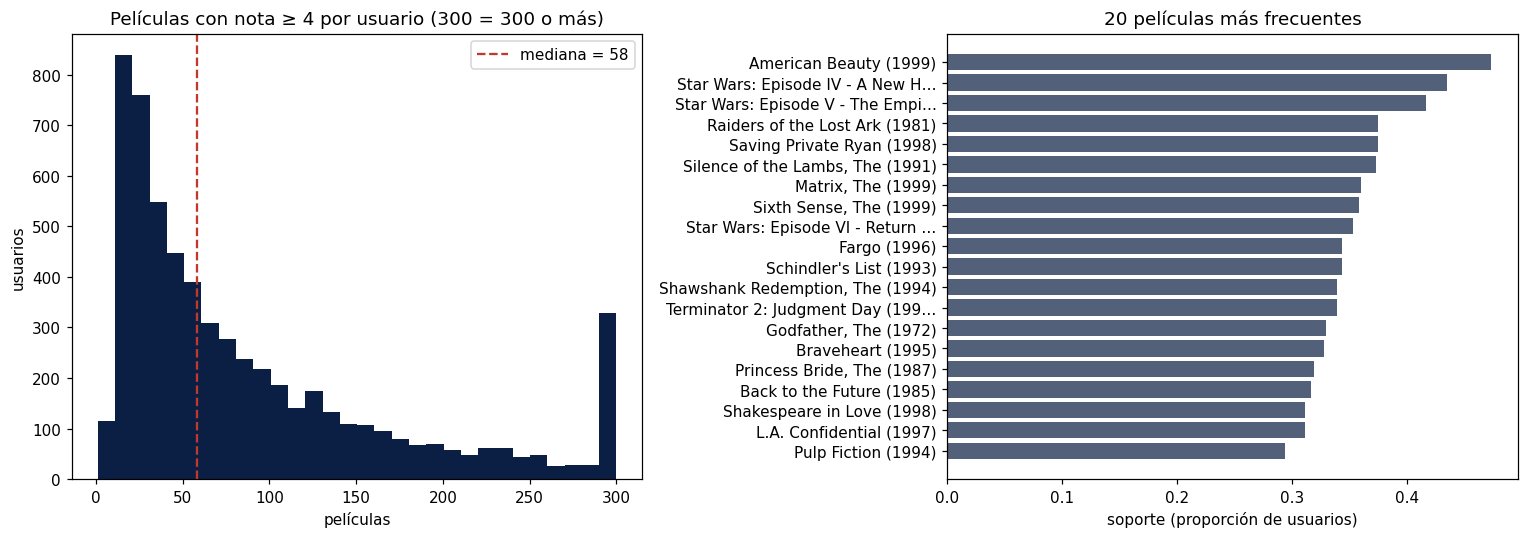

In [9]:
def corto(titulo, largo=32):
    # Acorta títulos largos para que quepan en los ejes de los gráficos
    return titulo if len(titulo) <= largo else titulo[:largo - 1] + "…"


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Izquierda: cuántas películas le gustan a cada usuario (los de 300 o más se agrupan)
ax[0].hist(peliculas_por_usuario.clip(upper=300), bins=30, color=AZUL)
ax[0].axvline(peliculas_por_usuario.median(), color=ROJO, linestyle="--",
              label=f"mediana = {peliculas_por_usuario.median():.0f}")
ax[0].set_title("Películas con nota ≥ 4 por usuario (300 = 300 o más)")
ax[0].set_xlabel("películas")
ax[0].set_ylabel("usuarios")
ax[0].legend()

# Derecha: las 20 películas más frecuentes
top20 = soporte_pelicula.head(20).sort_values()
ax[1].barh([corto(t) for t in top20.index], top20.values, color=GRIS)
ax[1].set_title("20 películas más frecuentes")
ax[1].set_xlabel("soporte (proporción de usuarios)")

plt.tight_layout()
plt.show()

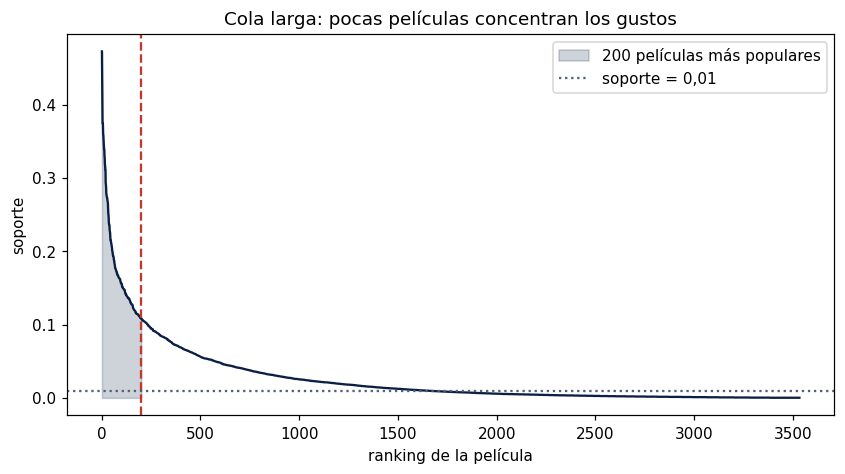

In [10]:
# Soporte de TODAS las películas, ordenadas de la más a la menos popular
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(1, len(soporte_pelicula) + 1), soporte_pelicula.values, color=AZUL)
ax.fill_between(range(1, 201), soporte_pelicula.values[:200], color=AZUL, alpha=0.2,
                label="200 películas más populares")
ax.axvline(200, color=ROJO, linestyle="--")
ax.axhline(0.01, color=GRIS, linestyle=":", label="soporte = 0,01")
ax.set_xlabel("ranking de la película")
ax.set_ylabel("soporte")
ax.set_title("Cola larga: pocas películas concentran los gustos")
ax.legend()
plt.show()

### 3.3 Co-ocurrencias

**Tabla cruzada de co-ocurrencias.** Multiplicando la matriz por su transpuesta obtenemos cuántos usuarios tienen cada par de películas entre sus favoritas. La diagonal es el conteo de cada película.

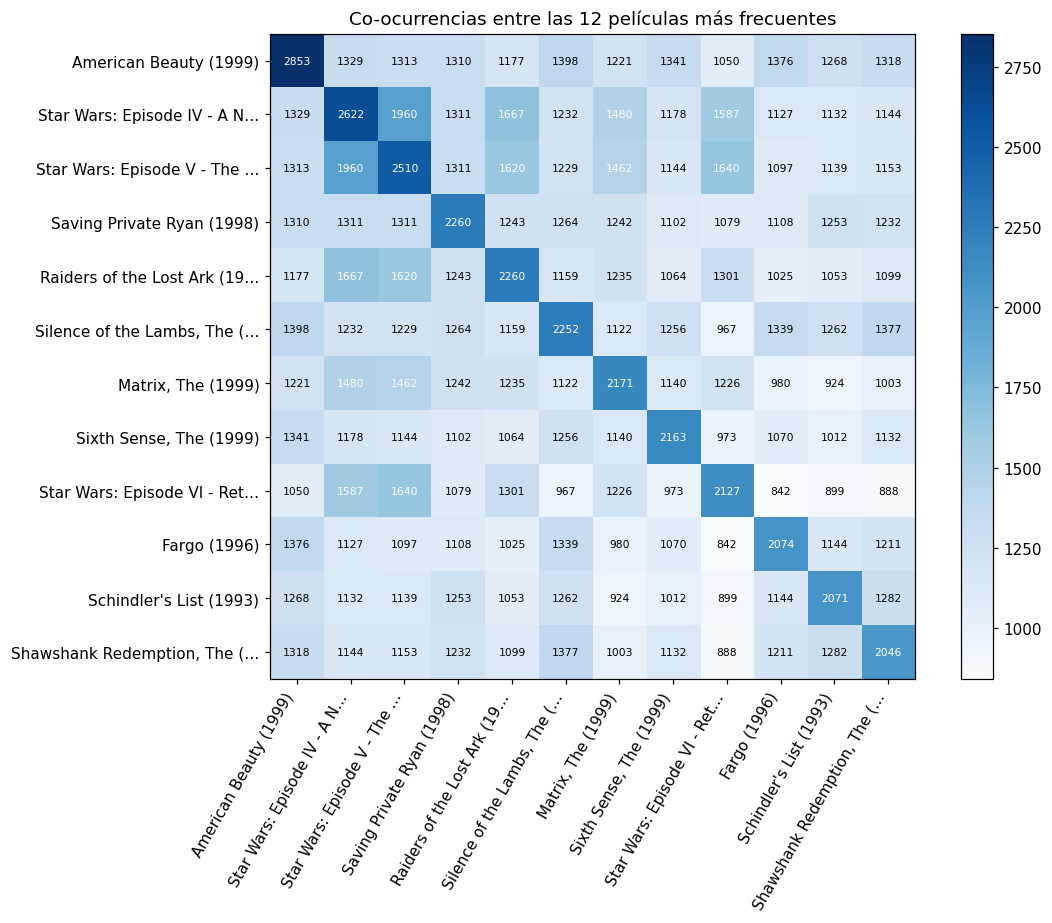

In [11]:
top12 = soporte_pelicula.head(12).index
sub = gustos[top12].astype(int)
coocurrencias = sub.T @ sub            # matriz 12 × 12 de conteos
etiquetas = [corto(t, 28) for t in top12]

fig, ax = plt.subplots(figsize=(10.5, 8.5))
imagen = ax.imshow(coocurrencias, cmap="Blues")
ax.set_xticks(range(12), etiquetas, rotation=60, ha="right")
ax.set_yticks(range(12), etiquetas)

# Escribimos el número dentro de cada celda
limite = coocurrencias.values.max() / 2
for i in range(12):
    for j in range(12):
        valor = coocurrencias.iat[i, j]
        ax.text(j, i, valor, ha="center", va="center", fontsize=7,
                color="white" if valor > limite else "black")

ax.set_title("Co-ocurrencias entre las 12 películas más frecuentes")
plt.colorbar(imagen, fraction=0.04)
plt.tight_layout()
plt.show()

### 3.4 Recorte a las películas más populares

Con 3.533 películas y un soporte bajo, el número de combinaciones explota y aparecen reglas de nicho basadas en muy pocos usuarios. Nos quedamos con las **200 películas más populares** y con los usuarios que tienen **al menos 2** de ellas (con una sola no hay asociación posible).

In [12]:
TOP_PELICULAS = 200

populares_200 = soporte_pelicula.head(TOP_PELICULAS).index
gustos_top = gustos[populares_200]

# Usuarios con al menos 2 de estas películas
gustos_top = gustos_top[gustos_top.sum(axis=1) >= 2].reset_index(drop=True)

cobertura = gustos[populares_200].values.sum() / gustos.values.sum()
print(f"Soporte de la película n.º {TOP_PELICULAS}: {soporte_pelicula.iloc[TOP_PELICULAS - 1]:.3f}")
print(f"Las {TOP_PELICULAS} películas concentran el {cobertura:.1%} de todas las evaluaciones positivas")
print(f"\nMatriz recortada: {gustos_top.shape[0]:,} usuarios × {gustos_top.shape[1]} películas")
print(f"Películas por usuario: promedio {gustos_top.sum(axis=1).mean():.1f} | mediana {gustos_top.sum(axis=1).median():.0f}")
print(f"Densidad: {gustos_top.values.mean():.2%}")

Soporte de la película n.º 200: 0.108
Las 200 películas concentran el 37.9% de todas las evaluaciones positivas

Matriz recortada: 6,004 usuarios × 200 películas
Películas por usuario: promedio 36.3 | mediana 27
Densidad: 18.13%


### 3.5 Hallazgos

1. **Cola larga muy marcada.** La matriz completa tiene una densidad de 2,7 %, y el 53,8 % de las películas le gusta a menos del 1 % de los usuarios. Por eso nos quedamos con las **200 películas más populares** (soporte ≥ 0,108), que concentran el 37,9 % de todas las evaluaciones positivas. El recorte se justifica con el **principio Apriori**: un conjunto de películas nunca puede ser más frecuente que cada película por separado, así que con un soporte mínimo de 0,10 o más (ver hallazgo 2) las películas fuera del top 200 no podrían aparecer en ninguna regla de todas formas. Incluirlas solo haría la matriz más grande y lenta, sin cambiar los resultados. La matriz recortada queda con 6.004 usuarios (cumple el mínimo de 3.000) y una densidad de 18,1 %.

2. **Las películas populares tienen soportes muy altos.** *American Beauty* le gusta al 47,3 % de los usuarios y las 20 más frecuentes superan el 29 %. A diferencia de *Groceries*, donde se usó un soporte de 0,01, aquí un umbral así generaría millones de combinaciones: **el soporte mínimo debe estar en un rango alto, entre 0,10 y 0,25**, que se compara en la tabla de sensibilidad.

3. **Usuarios muy desiguales.** La mediana es de 58 películas por usuario, pero el promedio sube a 95 por unos pocos usuarios muy activos (el máximo es 1.435). Estos "cinéfilos" aparecen en muchas combinaciones a la vez, lo que infla el soporte de los itemsets grandes.

4. **Las sagas generan las asociaciones más fuertes.** El par más frecuente es *Star Wars IV* y *Star Wars V* (1.960 usuarios): al 75 % de quienes les gustó la IV también les gustó la V, con un lift de 1,8. Se esperan reglas fuertes entre películas de una misma saga o del mismo estilo.

5. **Lo popular aparece con todo.** *American Beauty* comparte usuarios con todas las demás películas del top 12, pero con lifts de apenas 1,04 a 1,40: aparece junto a todo porque es popular, no por una afinidad específica. Por eso las reglas que terminan en películas muy populares tendrán confianza alta pero lift bajo, y **el lift debe ser el criterio principal** para ordenar reglas y recomendaciones. Esto también anticipa que la línea base de "las más populares" será un rival difícil en la evaluación.

## 4. Itemsets y reglas

De aquí en adelante trabajamos con la matriz recortada `gustos_top` (6.004 usuarios × 200 películas).

### 4.1 Cálculo a mano de una regla

Antes de usar los algoritmos, calculamos {Star Wars IV} ⇒ {Star Wars V} directamente con las fórmulas y luego verificamos con `mlxtend`:

$$sop = P(X \cap Z), \qquad conf = \frac{P(X \cap Z)}{P(X)}, \qquad lift = \frac{conf}{P(Z)}$$

In [13]:
X = "Star Wars: Episode IV - A New Hope (1977)"
Z = "Star Wars: Episode V - The Empire Strikes Back (1980)"

# 1) Conteos
n = len(gustos_top)
con_x = gustos_top[X].sum()
con_z = gustos_top[Z].sum()
con_ambos = (gustos_top[X] & gustos_top[Z]).sum()

# 2) Indicadores a mano
soporte = con_ambos / n
confianza = con_ambos / con_x
lift = confianza / (con_z / n)

print(f"n = {n:,} | con X = {con_x:,} | con Z = {con_z:,} | con ambos = {con_ambos:,}")
print(f"A mano  → soporte: {soporte:.3f} | confianza: {confianza:.3f} | lift: {lift:.3f}")

# 3) Verificación con mlxtend: buscamos la misma regla entre las generadas por el algoritmo
pares = apriori(gustos_top[[X, Z]], min_support=0.01, use_colnames=True)
verificacion = association_rules(pares, metric="confidence", min_threshold=0)
regla = verificacion[(verificacion["antecedents"] == frozenset({X})) &
                     (verificacion["consequents"] == frozenset({Z}))].iloc[0]
print(f"mlxtend → soporte: {regla['support']:.3f} | confianza: {regla['confidence']:.3f} | lift: {regla['lift']:.3f}")

n = 6,004 | con X = 2,622 | con Z = 2,510 | con ambos = 1,960
A mano  → soporte: 0.326 | confianza: 0.748 | lift: 1.788
mlxtend → soporte: 0.326 | confianza: 0.748 | lift: 1.788


Ambos cálculos coinciden. **Interpretación:** al 32,6 % de los usuarios le gustaron las dos películas; de quienes les gustó *Star Wars IV*, al 74,8 % también le gustó *Star Wars V*; y eso es 1,79 veces más de lo esperado si los gustos fueran independientes.

### 4.2 Sensibilidad de los umbrales

Probamos 3 valores de soporte mínimo (en el rango que sugirió la exploración) y 3 de confianza mínima, y contamos cuántos itemsets y reglas aparecen.

In [14]:
filas = []
for soporte in [0.10, 0.15, 0.20]:
    frecuentes = fpgrowth(gustos_top, min_support=soporte, use_colnames=True)
    fila = {"min_support": soporte, "itemsets": len(frecuentes)}
    for confianza in [0.5, 0.6, 0.7]:
        reglas_prueba = association_rules(frecuentes, metric="confidence", min_threshold=confianza)
        fila[f"reglas (conf ≥ {confianza})"] = len(reglas_prueba)
    filas.append(fila)

sensibilidad = pd.DataFrame(filas)
sensibilidad

,min_support,itemsets,reglas (conf ≥ 0.5),reglas (conf ≥ 0.6),reglas (conf ≥ 0.7)
0,0.100,3809,10954,7278,4102
1,0.150,452,591,341,198
2,0.200,111,105,59,22


**Umbrales elegidos: soporte mínimo = 0,15 y confianza mínima = 0,6.**

- Con **soporte 0,10** aparecen miles de reglas (más de 7.000 con confianza 0,6), imposibles de revisar y con mucha repetición entre ellas.
- Con **soporte 0,20** quedan muy pocas (59 con confianza 0,6), casi todas sobre la saga Star Wars.
- Con **soporte 0,15** obtenemos alrededor de 340 reglas: suficientes para recomendar y todavía interpretables. Cada regla se apoya en al menos 900 usuarios (0,15 × 6.004), lo que la hace confiable.
- La **confianza de 0,6** exige que la regla acierte en más de la mitad de los casos, sin dejar fuera asociaciones interesantes como pasa con 0,7.

### 4.3 Apriori vs. FP-Growth

Comprobamos que ambos algoritmos encuentran exactamente los mismos itemsets y comparamos su tiempo de ejecución (el menor de 3 repeticiones, para que la medición sea estable).

In [15]:
import time

def medir(algoritmo, soporte, repeticiones=3):
    # Ejecuta el algoritmo varias veces y devuelve el menor tiempo y el resultado
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        resultado = algoritmo(gustos_top, min_support=soporte, use_colnames=True)
        tiempos.append(time.perf_counter() - inicio)
    return min(tiempos), resultado


filas = []
for soporte in [0.20, 0.15, 0.10]:
    t_apriori, it_apriori = medir(apriori, soporte)
    t_fpgrowth, it_fpgrowth = medir(fpgrowth, soporte)

    # ¿Mismos itemsets con los mismos soportes?
    sop_apriori = dict(zip(it_apriori["itemsets"], it_apriori["support"]))
    sop_fpgrowth = dict(zip(it_fpgrowth["itemsets"], it_fpgrowth["support"]))
    iguales = (sop_apriori.keys() == sop_fpgrowth.keys() and
               all(np.isclose(sop_apriori[k], sop_fpgrowth[k]) for k in sop_apriori))

    filas.append({"min_support": soporte, "itemsets": len(it_apriori),
                  "mismos itemsets": iguales,
                  "Apriori (s)": t_apriori, "FP-Growth (s)": t_fpgrowth})

pd.DataFrame(filas)

,min_support,itemsets,mismos itemsets,Apriori (s),FP-Growth (s)
0,0.200,111,True,0.074,1.703
1,0.150,452,True,0.290,8.794
2,0.100,3809,True,4.564,86.906


Ambos algoritmos encuentran **exactamente los mismos itemsets con los mismos soportes**, como se espera: son dos caminos distintos para el mismo resultado.

En tiempo, en nuestra base **Apriori resultó entre 20 y 60 veces más rápido que FP-Growth** (por ejemplo, 4,3 s contra 85,7 s con soporte 0,10), al contrario de lo que pasaba en *Groceries* con soporte 0,001. La razón es que aquí la matriz tiene pocas columnas (200 películas) y es densa (18 %), y con soportes altos Apriori genera pocos candidatos y los cuenta muy rápido de forma vectorizada. FP-Growth tiene que construir un árbol con todas las transacciones, lo que le cuesta más cuando cada usuario tiene muchas películas. Su ventaja aparece con muchos ítems y soportes muy bajos, que no es nuestro caso. Por eso usamos Apriori para las reglas finales.

### 4.4 Reglas finales

In [16]:
SOPORTE_MIN = 0.15
CONFIANZA_MIN = 0.6

itemsets = apriori(gustos_top, min_support=SOPORTE_MIN, use_colnames=True)
itemsets["tamaño"] = itemsets["itemsets"].apply(len)
print("Itemsets frecuentes por tamaño:")
print(itemsets.groupby("tamaño")["itemsets"].count())

reglas = association_rules(itemsets.drop("tamaño", axis=1), metric="confidence", min_threshold=CONFIANZA_MIN)
print(f"\nCantidad de reglas: {len(reglas)}")

# Ampliamos el ancho de columna solo para esta tabla, porque los títulos son largos
with pd.option_context("display.max_colwidth", 200):
    display(tabla_reglas(reglas).head(15))

Itemsets frecuentes por tamaño:
tamaño
1    108
2    273
3     67
4      4
Name: itemsets, dtype: int64

Cantidad de reglas: 341


,regla,soporte,confianza,lift,leverage,conviccion
0,"{Raiders of the Lost Ark (1981), Star Wars: Episode V - The Empire Strikes Back (1980)} ⇒ {Indiana Jones and the Last Crusade (1989)}",0.164,0.608,2.815,0.106,2.000
1,"{Indiana Jones and the Last Crusade (1989)} ⇒ {Raiders of the Lost Ark (1981), Star Wars: Episode V - The Empire Strikes Back (1980)}",0.164,0.759,2.815,0.106,3.035
2,{Alien (1979)} ⇒ {Aliens (1986)},0.172,0.636,2.689,0.108,2.100
3,{Aliens (1986)} ⇒ {Alien (1979)},0.172,0.727,2.689,0.108,2.672
4,"{Indiana Jones and the Last Crusade (1989)} ⇒ {Raiders of the Lost Ark (1981), Star Wars: Episode IV - A New Hope (1977)}",0.160,0.742,2.674,0.100,2.805
5,"{Star Wars: Episode V - The Empire Strikes Back (1980), Terminator 2: Judgment Day (1991)} ⇒ {Terminator, The (1984)}",0.164,0.737,2.628,0.102,2.732
6,"{Godfather: Part II, The (1974)} ⇒ {Godfather, The (1972)}",0.208,0.867,2.618,0.129,5.027
7,"{Godfather, The (1972)} ⇒ {Godfather: Part II, The (1974)}",0.208,0.629,2.618,0.129,2.049
8,"{Star Wars: Episode IV - A New Hope (1977), Terminator 2: Judgment Day (1991)} ⇒ {Terminator, The (1984)}",0.163,0.730,2.604,0.100,2.664
9,"{Matrix, The (1999), Star Wars: Episode V - The Empire Strikes Back (1980)} ⇒ {Star Wars: Episode IV - A New Hope (1977), Star Wars: Episode VI - Return of the Jedi (1983)}",0.167,0.686,2.595,0.103,2.343


**Interpretación de las reglas** (en lenguaje de una plataforma de streaming):

1. **{El Padrino II} ⇒ {El Padrino}** (confianza 0,87; lift 2,62; convicción 5,0). Al 87 % de quienes les gustó la segunda parte también les gustó la primera, 2,6 veces más de lo normal. Es la regla más confiable: a quien termina *El Padrino II* se le puede recomendar la original casi sin riesgo de fallar.
2. **{Aliens} ⇒ {Alien}** (confianza 0,73; lift 2,69). Las sagas se ven completas: quien disfrutó la secuela es un fuerte candidato para la película original de 1979.
3. **{Raiders of the Lost Ark, Star Wars V} ⇒ {Indiana Jones and the Last Crusade}** (confianza 0,61; lift 2,82, el más alto de todas las reglas). Muestra un perfil de **aventura de los 80** con el sello de George Lucas, que participó en las tres películas: a quien le gustan la primera de Indiana Jones y *El Imperio Contraataca*, *La Última Cruzada* le gusta con una probabilidad casi tres veces mayor que al usuario promedio.
4. **{Star Wars V, Terminator 2} ⇒ {Terminator}** (confianza 0,74; lift 2,63). Combina dos franquicias de ciencia ficción y acción: quien disfruta ambas tiene mucha afinidad con la *Terminator* original.
5. **{Die Hard} ⇒ {Terminator}** (confianza 0,71; lift 2,53). Une películas de acción de los 80 que no son de la misma saga: aquí la regla aporta algo que un simple "ver la secuela" no captaría, y es el tipo de recomendación que ayuda a descubrir catálogo.

Las reglas suelen aparecer **en pares** ({A} ⇒ {B} y {B} ⇒ {A}) con el mismo lift, porque el lift es simétrico, pero con distinta confianza: por ejemplo, {El Padrino II} ⇒ {El Padrino} tiene confianza 0,87, mientras que la inversa tiene 0,63, porque *El Padrino* es más popular que su secuela.

### 4.5 ¿Por qué no basta la confianza?

*American Beauty* le gusta al 47,5 % de los usuarios. Por eso, casi cualquier regla X ⇒ {American Beauty} tiene una confianza cercana a 0,5, aunque no exista una afinidad real. El lift corrige esto comparando con lo esperado si los gustos fueran independientes.

In [17]:
def evaluar_regla(antecedente, consecuente):
    # Calcula soporte, confianza, P(consecuente) y lift de una regla simple {antecedente} ⇒ {consecuente}
    tiene_x = gustos_top[antecedente]
    tiene_z = gustos_top[consecuente]
    p_x = tiene_x.mean()
    p_z = tiene_z.mean()
    p_xz = (tiene_x & tiene_z).mean()
    return {
        "regla": f"{{{antecedente}}} ⇒ {{{consecuente}}}",
        "soporte": p_xz,
        "confianza": p_xz / p_x,
        "P(consecuente)": p_z,
        "lift": p_xz / (p_x * p_z),
    }


with pd.option_context("display.max_colwidth", 200):
    display(pd.DataFrame([
        evaluar_regla("Star Trek: The Wrath of Khan (1982)", "American Beauty (1999)"),
        evaluar_regla("Jurassic Park (1993)", "American Beauty (1999)"),
        evaluar_regla("Godfather: Part II, The (1974)", "Godfather, The (1972)"),
    ]))

,regla,soporte,confianza,P(consecuente),lift
0,{Star Trek: The Wrath of Khan (1982)} ⇒ {American Beauty (1999)},0.080,0.478,0.475,1.006
1,{Jurassic Park (1993)} ⇒ {American Beauty (1999)},0.145,0.504,0.475,1.061
2,"{Godfather: Part II, The (1974)} ⇒ {Godfather, The (1972)}",0.208,0.867,0.331,2.618


La regla **{Star Trek II} ⇒ {American Beauty}** tiene una confianza de 0,48: parece que "a casi la mitad de los fans de Star Trek les gusta American Beauty". Pero P(Z) = 0,475, es decir, a casi la mitad de **todos** los usuarios les gusta American Beauty, sean fans de Star Trek o no. Por eso el lift es ≈ 1,0: ver Star Trek **no cambia en nada** la probabilidad de que te guste American Beauty. Lo mismo ocurre con *Jurassic Park* (lift 1,06).

En cambio, **{El Padrino II} ⇒ {El Padrino}** tiene confianza 0,87 con P(Z) = 0,33: aquí sí hay una afinidad real (lift 2,62). Una plataforma usaría solo esta última, y recomendar *American Beauty* a un fan de Star Trek sería equivalente a recomendarla al azar.

Estas reglas se evalúan por separado con `evaluar_regla` para ilustrar el problema; algunas, como la de *Star Trek II* (soporte 0,08), ni siquiera superan el soporte mínimo de 0,15, por lo que no forman parte de las 341 reglas finales.

## 5. Fisher, redundantes y consulta dirigida

### 5.1 Significancia estadística (test exacto de Fisher)

Con muchas reglas, algunas pueden aparecer por azar. Para cada regla se arma la tabla de contingencia 2×2 y se aplica el test de Fisher unilateral (¿tener X aumenta la probabilidad de Z?). Como se hacen muchas pruebas a la vez, los p-valores se corrigen con el método de Holm.

| | Tiene Z | No tiene Z |
|---|---|---|
| **Tiene X** | a | b |
| **No tiene X** | c | d |

In [18]:
def p_valor_fisher(antecedente, consecuente):
    # Tabla 2×2 de la regla y test de Fisher unilateral (¿X aumenta la probabilidad de Z?)
    tiene_x = gustos_top[list(antecedente)].all(axis=1)
    tiene_z = gustos_top[list(consecuente)].all(axis=1)

    a = (tiene_x & tiene_z).sum()
    b = (tiene_x & ~tiene_z).sum()
    c = (~tiene_x & tiene_z).sum()
    d = (~tiene_x & ~tiene_z).sum()

    _, p = fisher_exact([[a, b], [c, d]], alternative="greater")
    return p


reglas["p_valor"] = [p_valor_fisher(x, z) for x, z in zip(reglas["antecedents"], reglas["consequents"])]

# Corrección de Holm por comparaciones múltiples
reglas["significativa"], reglas["p_ajustado"], _, _ = multipletests(reglas["p_valor"], alpha=0.01, method="holm")

print(f"Reglas significativas (α = 0,01, Holm): {reglas['significativa'].sum()} de {len(reglas)}")
print(f"Mayor p-valor ajustado: {reglas['p_ajustado'].max():.1e}")

resumen = pd.DataFrame({
    "regla": reglas["antecedents"].apply(texto_itemset) + " ⇒ " + reglas["consequents"].apply(texto_itemset),
    "confianza": reglas["confidence"],
    "lift": reglas["lift"],
    "p_ajustado": reglas["p_ajustado"].apply(lambda p: f"{p:.1e}"),   # notación científica: son muy pequeños
    "significativa": reglas["significativa"],
})
with pd.option_context("display.max_colwidth", 200):
    display(resumen.sort_values("lift").head(5).reset_index(drop=True))

Reglas significativas (α = 0,01, Holm): 341 de 341
Mayor p-valor ajustado: 1.6e-31


,regla,confianza,lift,p_ajustado,significativa
0,{One Flew Over the Cuckoo's Nest (1975)} ⇒ {American Beauty (1999)},0.604,1.271,1.6e-31,True
1,{Groundhog Day (1993)} ⇒ {American Beauty (1999)},0.611,1.286,7.6e-39,True
2,{Schindler's List (1993)} ⇒ {American Beauty (1999)},0.613,1.289,1.3e-53,True
3,"{Sixth Sense, The (1999)} ⇒ {American Beauty (1999)}",0.620,1.305,2.3e-63,True
4,"{Silence of the Lambs, The (1991)} ⇒ {American Beauty (1999)}",0.621,1.306,3.4e-68,True


**Las 341 reglas son significativas**, incluso las de menor lift (que se muestran arriba), y el mayor p-valor ajustado es del orden de 10⁻³¹. Esto no significa que el test no sirva: con 6.004 usuarios, un soporte mínimo de 0,15 (cada regla se apoya en al menos 900 usuarios) y lifts de 1,27 o más, la probabilidad de ver esas asociaciones por azar es prácticamente cero. En *Groceries*, con umbrales mucho más bajos, el test sí era necesario para descartar reglas. Aquí confirma que los umbrales elegidos en la sección 4 ya eran suficientemente exigentes.

### 5.2 Reglas redundantes

**Regla redundante:** X ⇒ Z es redundante si existe una regla más simple X′ ⇒ Z, con X′ ⊂ X, que tiene igual o mayor confianza. Agregar películas al antecedente no aporta información nueva.

In [19]:
def marcar_redundantes(reglas):
    # Para cada regla, buscamos otra con el mismo consecuente y un antecedente más pequeño
    # (subconjunto estricto) que tenga confianza igual o mayor
    redundante = []
    for _, regla in reglas.iterrows():
        mismas_z = reglas[reglas["consequents"] == regla["consequents"]]
        mas_simples = mismas_z[mismas_z["antecedents"].apply(lambda x: x < regla["antecedents"])]
        redundante.append((mas_simples["confidence"] >= regla["confidence"]).any())
    return np.array(redundante)


# 1) Nuestras reglas finales (soporte 0,15; confianza 0,6)
reglas["redundante"] = marcar_redundantes(reglas)
print(f"Reglas redundantes (soporte 0,15): {reglas['redundante'].sum()} de {len(reglas)}")

# 2) Con un soporte más bajo (0,10) aparecen antecedentes más largos y con ellos la redundancia
itemsets_bajos = apriori(gustos_top, min_support=0.10, use_colnames=True)
reglas_bajas = association_rules(itemsets_bajos, metric="confidence", min_threshold=CONFIANZA_MIN)
reglas_bajas["redundante"] = marcar_redundantes(reglas_bajas)
print(f"Reglas redundantes (soporte 0,10): {reglas_bajas['redundante'].sum()} de {len(reglas_bajas)}")

# Ejemplo: la regla redundante de mayor lift y la regla más simple que la explica
ejemplo = reglas_bajas[reglas_bajas["redundante"]].sort_values("lift", ascending=False).iloc[0]
mas_simple = reglas_bajas[(reglas_bajas["consequents"] == ejemplo["consequents"]) &
                          (reglas_bajas["antecedents"].apply(lambda x: x < ejemplo["antecedents"])) &
                          (reglas_bajas["confidence"] >= ejemplo["confidence"])].sort_values("confidence", ascending=False).iloc[0]
print(f"\nRedundante: {texto_itemset(ejemplo['antecedents'])} ⇒ {texto_itemset(ejemplo['consequents'])}"
      f"  (conf = {ejemplo['confidence']:.3f})")
print(f"Más simple: {texto_itemset(mas_simple['antecedents'])} ⇒ {texto_itemset(mas_simple['consequents'])}"
      f"  (conf = {mas_simple['confidence']:.3f})")

Reglas redundantes (soporte 0,15): 0 de 341
Reglas redundantes (soporte 0,10): 36 de 7278

Redundante: {Raiders of the Lost Ark (1981), Star Wars: Episode IV - A New Hope (1977), Star Wars: Episode V - The Empire Strikes Back (1980), Terminator, The (1984)} ⇒ {Alien (1979)}  (conf = 0.702)
Más simple: {Star Wars: Episode IV - A New Hope (1977), Star Wars: Episode V - The Empire Strikes Back (1980), Terminator, The (1984)} ⇒ {Alien (1979)}  (conf = 0.702)


**Con nuestros umbrales no hay reglas redundantes.** Con soporte 0,15 los antecedentes tienen como máximo 3 películas, y en este dominio agregar una película que también le gustó al usuario casi siempre *aumenta* la confianza, porque refuerza el perfil de gustos.

Para comprobar que la función detecta el problema, la aplicamos a las 7.278 reglas con soporte 0,10: ahí aparecen **36 reglas redundantes**. Por ejemplo, agregar *Raiders of the Lost Ark* a {Star Wars IV, Star Wars V, Terminator} no cambia la confianza de recomendar *Alien* (0,702 en ambos casos): saber que a alguien le gustó *Raiders* no aporta nada nuevo si ya sabemos que le gustaron las otras tres. Esto confirma otra ventaja del soporte 0,15: además de reducir el número de reglas, evita la redundancia.

Nos quedamos con las reglas **significativas y no redundantes**:

In [20]:
reglas_finales = reglas[reglas["significativa"] & ~reglas["redundante"]].reset_index(drop=True)
print(f"Reglas finales: {len(reglas_finales)} (significativas y no redundantes)")

Reglas finales: 341 (significativas y no redundantes)


### 5.3 Consulta dirigida: ¿qué anticipa que a un usuario le guste *Gladiator*?

*Gladiator* (2000) es el estreno más reciente entre las películas más populares de la base, así que es el tipo de título que una plataforma querría promocionar. Fijamos como consecuente esa película y buscamos qué gustos la anticipan. Como le gusta solo al 25 % de los usuarios, usamos los itemsets con soporte 0,10 y una confianza mínima de 0,3 para no perder reglas.

In [21]:
CONSECUENTE = "Gladiator (2000)"

reglas_consulta = association_rules(itemsets_bajos, metric="confidence", min_threshold=0.3)
reglas_consulta = reglas_consulta[reglas_consulta["consequents"] == frozenset({CONSECUENTE})]

print(f"P({CONSECUENTE}) = {gustos_top[CONSECUENTE].mean():.3f}")
print(f"Reglas que terminan en {CONSECUENTE}: {len(reglas_consulta)}")
with pd.option_context("display.max_colwidth", 200):
    display(tabla_reglas(reglas_consulta).head(5))

P(Gladiator (2000)) = 0.251
Reglas que terminan en Gladiator (2000): 35


,regla,soporte,confianza,lift,leverage,conviccion
0,"{Matrix, The (1999), Saving Private Ryan (1998)} ⇒ {Gladiator (2000)}",0.103,0.497,1.981,0.051,1.489
1,"{Braveheart (1995), Saving Private Ryan (1998)} ⇒ {Gladiator (2000)}",0.102,0.488,1.946,0.049,1.463
2,"{American Beauty (1999), Sixth Sense, The (1999)} ⇒ {Gladiator (2000)}",0.102,0.458,1.825,0.046,1.382
3,"{Matrix, The (1999), Star Wars: Episode V - The Empire Strikes Back (1980)} ⇒ {Gladiator (2000)}",0.108,0.442,1.762,0.047,1.342
4,"{Matrix, The (1999), Terminator 2: Judgment Day (1991)} ⇒ {Gladiator (2000)}",0.101,0.439,1.752,0.043,1.336


Las combinaciones que mejor anticipan *Gladiator* son **{Matrix, Saving Private Ryan}** (confianza 0,50; lift 1,98) y **{Braveheart, Saving Private Ryan}** (confianza 0,49; lift 1,95): a quienes les gustan las películas épicas y de acción, *Gladiator* les gusta con el doble de probabilidad que al usuario promedio. Para la plataforma, esto define el **público objetivo de la campaña**: en vez de mostrar el estreno a todos, conviene destacarlo a los usuarios que valoraron bien estas películas.

### 5.4 Visualización de reglas

En todos los gráficos se puede pasar el mouse sobre los puntos, nodos y flechas para ver soporte, confianza y lift, arrastrar nodos y hacer zoom.

In [22]:
import html
import matplotlib.colors as mcolors
from pyvis.network import Network
from IPython.display import HTML, display

# Soporte de cada película en la matriz recortada (equivale a soporte_producto de la guía)
soporte_top = gustos_top.mean()


def color_lift(valor, minimo, maximo):
    # Asigna un tono de rojo según el lift: más oscuro = asociación más fuerte
    escala = plt.get_cmap("Reds")
    proporcion = (valor - minimo) / (maximo - minimo) if maximo > minimo else 1
    return mcolors.to_hex(escala(0.25 + 0.75 * proporcion))


def mostrar_red(red, alto=650):
    # pyvis genera una página HTML completa; la mostramos dentro de un iframe para que funcione en Colab
    pagina = red.generate_html()
    display(HTML(f'<iframe srcdoc="{html.escape(pagina)}" width="100%" height="{alto + 20}" '
                 f'style="border:1px solid #ddd; border-radius:6px"></iframe>'))

**a) Dispersión interactiva de reglas.** Cada punto es una regla; al pasar el mouse se ve cuál es.

In [23]:
dispersion = tabla_reglas(reglas_finales)

figura = px.scatter(dispersion, x="soporte", y="confianza", color="lift",
                    hover_name="regla", hover_data={"soporte": ":.3f", "confianza": ":.3f", "lift": ":.2f"},
                    color_continuous_scale="Reds", height=500,
                    title=f"{len(dispersion)} reglas finales (minsop = {SOPORTE_MIN}; minconf = {CONFIANZA_MIN})")
figura.update_traces(marker=dict(size=8, line=dict(width=0.3, color="white")))
figura.show()

**b) Grafo de reglas** con las 25 reglas de mayor lift.

- Cuadros azules: películas.
- Círculos rojos: reglas. Tamaño = soporte; color = lift.
- Las flechas van del antecedente a la regla y de la regla al consecuente.

In [24]:
def grafo_reglas(reglas, alto=650):
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = reglas["lift"].min(), reglas["lift"].max()
    soporte_max = reglas["support"].max()

    for i, regla in reglas.reset_index(drop=True).iterrows():
        nombre = f"regla {i + 1}"
        detalle = (f"{texto_itemset(regla['antecedents'])} ⇒ {texto_itemset(regla['consequents'])}\n"
                   f"soporte:   {regla['support']:.3f}\n"
                   f"confianza: {regla['confidence']:.3f}\n"
                   f"lift:      {regla['lift']:.2f}")

        # Nodo de la regla
        red.add_node(nombre, label=" ", title=detalle, shape="dot",
                     size=10 + 25 * regla["support"] / soporte_max,
                     color=color_lift(regla["lift"], lift_min, lift_max))

        # Nodos de películas y flechas
        for pelicula in regla["antecedents"] | regla["consequents"]:
            red.add_node(pelicula, label=corto(pelicula, 28), shape="box", color="#e6e9ef",
                         font={"color": AZUL, "size": 16}, title=f"{pelicula}\nsoporte: {soporte_top[pelicula]:.3f}")
        for pelicula in regla["antecedents"]:
            red.add_edge(pelicula, nombre, color=GRIS)
        for pelicula in regla["consequents"]:
            red.add_edge(nombre, pelicula, color=GRIS)

    red.repulsion(node_distance=160, spring_length=140)
    return red


mostrar_red(grafo_reglas(reglas_finales.sort_values("lift", ascending=False).head(25)))

**c) Mapa de flujo película → película.** Cada flecha es una regla simple {A} ⇒ {B}: "a quien le gustó A, también le gustó B".

- Grosor de la flecha = confianza.
- Color de la flecha = lift (más rojo, asociación más fuerte).
- Tamaño de la película = soporte (qué tan popular es).

In [25]:
# Reglas película → película: itemsets de tamaño 2 como máximo
pares = apriori(gustos_top, min_support=0.10, use_colnames=True, max_len=2)
reglas_pares = association_rules(pares, metric="confidence", min_threshold=0.3)
reglas_pares["desde"] = reglas_pares["antecedents"].apply(lambda x: next(iter(x)))
reglas_pares["hacia"] = reglas_pares["consequents"].apply(lambda x: next(iter(x)))

# Solo asociaciones positivas (lift > 1,2), para no mostrar flechas sin información
reglas_pares = reglas_pares[reglas_pares["lift"] > 1.2].reset_index(drop=True)
print(f"Reglas película → película: {len(reglas_pares)} entre {reglas_pares['desde'].nunique()} películas")


def mapa_flujo(reglas_pares, lift_minimo=2.4, alto=700):
    seleccion = reglas_pares[reglas_pares["lift"] >= lift_minimo]
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = seleccion["lift"].min(), seleccion["lift"].max()

    # Nodos: un círculo por película, tamaño según su soporte
    for pelicula in set(seleccion["desde"]) | set(seleccion["hacia"]):
        red.add_node(pelicula, label=corto(pelicula, 28), shape="dot", color=AZUL,
                     size=10 + 60 * soporte_top[pelicula],
                     font={"size": 22, "color": AZUL, "strokeWidth": 6, "strokeColor": "white"},
                     title=f"{pelicula}\nsoporte: {soporte_top[pelicula]:.3f}")

    # Flechas: una por regla
    for _, r in seleccion.iterrows():
        red.add_edge(r["desde"], r["hacia"],
                     width=1 + 8 * r["confidence"],
                     color=color_lift(r["lift"], lift_min, lift_max),
                     title=(f"{r['desde']} ⇒ {r['hacia']}\n"
                            f"soporte:   {r['support']:.3f}\n"
                            f"confianza: {r['confidence']:.3f}\n"
                            f"lift:      {r['lift']:.2f}"))

    red.barnes_hut(gravity=-9000, spring_length=160)
    red.options.interaction.hover = True
    print(f"Mostrando {len(seleccion)} reglas con lift ≥ {lift_minimo}")
    return red


# Pruebe con lift_minimo = 2.2 (más flechas) o 2.6 (solo las asociaciones más fuertes)
mostrar_red(mapa_flujo(reglas_pares, lift_minimo=2.4))

Reglas película → película: 2383 entre 129 películas
Mostrando 65 reglas con lift ≥ 2.4


**Lectura de los gráficos.**

- En la **dispersión** casi todas las reglas tienen soporte entre 0,15 y 0,20; las pocas con más soporte corresponden a la saga Star Wars, la más popular de la base. Las reglas más rojas (mayor lift) no son las de mayor soporte: las asociaciones más fuertes están en grupos de usuarios más específicos.
- En el **grafo de reglas** se ven tres zonas: un bloque denso alrededor de **Star Wars, Indiana Jones y Matrix** (aventura y ciencia ficción), las sagas cerradas como **El Padrino** y **Alien/Aliens**, y el par **GoodFellas → Pulp Fiction** (cine criminal).
- El **mapa de flujo** muestra que los usuarios forman **comunidades de gusto** que el algoritmo descubrió sin conocer los géneros de las películas:
  - **Animación familiar:** Aladdin, Toy Story, Toy Story 2 y Bug's Life.
  - **Cine criminal de los 90:** Pulp Fiction, Reservoir Dogs, GoodFellas, The Usual Suspects y Se7en.
  - **Acción de los 80:** Die Hard, Lethal Weapon, Terminator, Predator, Aliens y Alien.
  - **Clásicos:** Casablanca, Citizen Kane y The Graduate.
  - **Ciencia ficción de culto:** 2001: Odisea del espacio, Dr. Strangelove, Encuentros cercanos y Blade Runner.
  - **Comedias juveniles de los 80:** Ferris Bueller y The Breakfast Club; y **comedia clásica:** Monty Python y Young Frankenstein.

Para una plataforma, cada comunidad es una "fila" de recomendaciones posible (por ejemplo, *"Porque te gustó Pulp Fiction: más cine criminal"*), y las películas que conectan dos comunidades, como *Terminator* entre acción y ciencia ficción, son buenas puertas de entrada para que el usuario descubra un género nuevo.

### 5.5 Cadena de películas: "esto lleva a esto, que lleva a esto…"

Partimos de una película y seguimos, paso a paso, la regla más fuerte hacia una película nueva. Al final revisamos si la última película tiene una regla que vuelve a alguna ya visitada (ciclo).

El criterio puede ser:

- `"lift"`: la asociación más fuerte (recomendaciones más afines al perfil).
- `"confidence"`: la más probable (tiende a llevar a las películas más populares).

In [26]:
def cadena_de_compras(inicio, pasos=6, criterio="lift"):
    camino = [inicio]
    tramos = []

    # Avanzamos mientras haya una regla hacia una película que aún no esté en el camino
    while len(camino) < pasos:
        salidas = reglas_pares[(reglas_pares["desde"] == camino[-1]) & ~reglas_pares["hacia"].isin(camino)]
        if salidas.empty:
            break
        mejor = salidas.sort_values(criterio, ascending=False).iloc[0]
        tramos.append(mejor)
        camino.append(mejor["hacia"])

    # ¿La última película vuelve a alguna anterior?
    regreso = reglas_pares[(reglas_pares["desde"] == camino[-1]) & reglas_pares["hacia"].isin(camino[:-1])]
    regreso = regreso.sort_values(criterio, ascending=False).head(1)

    tabla = pd.DataFrame({
        "paso": range(1, len(tramos) + 1),
        "regla": [f"{t['desde']} ⇒ {t['hacia']}" for t in tramos],
        "soporte": [t["support"] for t in tramos],
        "confianza": [t["confidence"] for t in tramos],
        "lift": [t["lift"] for t in tramos],
    })
    return camino, tabla, regreso


def mostrar_cadena(inicio, pasos=6, criterio="lift"):
    camino, tabla, regreso = cadena_de_compras(inicio, pasos, criterio)

    texto = " → ".join(camino)
    if not regreso.empty:
        texto += f"  ↺ vuelve a {regreso.iloc[0]['hacia']}"
    print(texto)
    with pd.option_context("display.max_colwidth", 200):
        display(tabla)

    # Dibujo: cada película en una columna, de izquierda a derecha
    red = Network(height="320px", width="100%", directed=True, cdn_resources="remote")
    for nivel, pelicula in enumerate(camino):
        red.add_node(pelicula, label=corto(pelicula, 22), x=230 * nivel, y=0, shape="box",
                     title=pelicula,
                     color=AZUL if nivel == 0 else "#e6e9ef",
                     font={"color": "white" if nivel == 0 else AZUL, "size": 14})

    for _, t in tabla.iterrows():
        desde, hacia = t["regla"].split(" ⇒ ")
        red.add_edge(desde, hacia, width=1 + 8 * t["confianza"], color=ROJO, smooth=False,
                     label=f"conf {t['confianza']:.2f} | lift {t['lift']:.2f}",
                     title=f"{t['regla']}\nsoporte: {t['soporte']:.3f}\nconfianza: {t['confianza']:.3f}\nlift: {t['lift']:.2f}")

    if not regreso.empty:
        r = regreso.iloc[0]
        # Flecha punteada de regreso (sin etiqueta para no tapar la cadena; el detalle aparece al pasar el mouse)
        red.add_edge(r["desde"], r["hacia"], dashes=True, color=GRIS, width=2,
                     title=f"vuelve: {r['desde']} ⇒ {r['hacia']}\nconfianza: {r['confidence']:.3f}\nlift: {r['lift']:.2f}",
                     smooth={"enabled": True, "type": "curvedCW", "roundness": 0.5})

    # Posiciones fijas (sin física) para que la cadena se lea de izquierda a derecha
    red.set_options('{"physics": {"enabled": false}, "edges": {"font": {"size": 12, "align": "top"}}}')
    mostrar_red(red, alto=320)


mostrar_cadena("Pulp Fiction (1994)", criterio="lift")
mostrar_cadena("Pulp Fiction (1994)", criterio="confidence")

Pulp Fiction (1994) → Reservoir Dogs (1992) → Usual Suspects, The (1995) → Seven (Se7en) (1995) → Silence of the Lambs, The (1991) → Sling Blade (1996)  ↺ vuelve a Pulp Fiction (1994)


,paso,regla,soporte,confianza,lift
0,1,Pulp Fiction (1994) ⇒ Reservoir Dogs (1992),0.131,0.443,2.673
1,2,"Reservoir Dogs (1992) ⇒ Usual Suspects, The (1995)",0.125,0.753,2.811
2,3,"Usual Suspects, The (1995) ⇒ Seven (Se7en) (1995)",0.108,0.404,2.715
3,4,"Seven (Se7en) (1995) ⇒ Silence of the Lambs, The (1991)",0.116,0.782,2.085
4,5,"Silence of the Lambs, The (1991) ⇒ Sling Blade (1996)",0.120,0.321,1.962


Pulp Fiction (1994) → American Beauty (1999) → Silence of the Lambs, The (1991) → Shawshank Redemption, The (1994) → Schindler's List (1993) → Saving Private Ryan (1998)  ↺ vuelve a American Beauty (1999)


,paso,regla,soporte,confianza,lift
0,1,Pulp Fiction (1994) ⇒ American Beauty (1999),0.209,0.708,1.491
1,2,"American Beauty (1999) ⇒ Silence of the Lambs, The (1991)",0.233,0.490,1.306
2,3,"Silence of the Lambs, The (1991) ⇒ Shawshank Redemption, The (1994)",0.229,0.611,1.794
3,4,"Shawshank Redemption, The (1994) ⇒ Schindler's List (1993)",0.214,0.627,1.817
4,5,Schindler's List (1993) ⇒ Saving Private Ryan (1998),0.209,0.605,1.609


Las dos cadenas que parten de *Pulp Fiction* muestran el mismo efecto de la sección 4.5:

- **Por lift:** *Pulp Fiction → Reservoir Dogs → The Usual Suspects → Se7en → El silencio de los inocentes → Sling Blade*, y vuelve a *Pulp Fiction*. Se mantiene dentro del cine criminal y de suspenso, con lifts entre 2,0 y 2,8.
- **Por confianza:** *Pulp Fiction → American Beauty → El silencio de los inocentes → Sueño de fuga → La lista de Schindler → Rescatando al soldado Ryan*, y vuelve a *American Beauty*. Salta enseguida a las películas más populares de la base, con lifts de apenas 1,3 a 1,8: cada paso es "probable" porque esas películas le gustan a casi todos, no por una afinidad con el punto de partida. Que el ciclo regrese justamente a *American Beauty*, la película más popular, muestra que la confianza siempre termina girando en torno a lo más visto.

**Explorador interactivo.** Elija la película de partida, el número de pasos y el criterio.

In [27]:
import ipywidgets as widgets

opciones = sorted(reglas_pares["desde"].unique())
widgets.interact(mostrar_cadena,
                 inicio=widgets.Dropdown(options=opciones, value="Pulp Fiction (1994)", description="Inicio",
                                         layout=widgets.Layout(width="450px")),
                 pasos=widgets.IntSlider(value=6, min=2, max=10, description="Pasos"),
                 criterio=widgets.ToggleButtons(options=["lift", "confidence"], description="Criterio"));

interactive(children=(Dropdown(description='Inicio', index=84, layout=Layout(width='450px'), options=('2001: A…

## 6. Recomendador

Es el principio "a quienes les gustó esto, también les gustó…":

1. Tomamos las películas que le gustaron al usuario (su canasta).
2. Activamos las reglas cuyo antecedente está completamente dentro de la canasta.
3. Recomendamos los consecuentes que el usuario aún no tiene, ordenados por lift (o por confianza).
4. Si ninguna regla se activa (**arranque en frío**), completamos con las películas más populares.

### 6.1 Reglas para recomendar

Las reglas de la sección 4 (soporte 0,15) sirven para analizar, pero son pocas para recomendar: solo pueden sugerir unas 30 películas distintas. Para el recomendador usamos umbrales más bajos y reglas de **una película → una película**, y comparamos cuántas películas distintas puede llegar a recomendar cada configuración.

In [28]:
def minar_reglas(datos, soporte=0.07, confianza=0.4, max_len=2):
    # Mina reglas y deja solo las de un consecuente (más fáciles de recomendar)
    frecuentes = apriori(datos, min_support=soporte, use_colnames=True, max_len=max_len)
    reglas = association_rules(frecuentes, metric="confidence", min_threshold=confianza)
    reglas = reglas[reglas["consequents"].apply(len) == 1].copy()
    reglas["producto"] = reglas["consequents"].apply(lambda z: next(iter(z)))
    return reglas.reset_index(drop=True)


# Comparación de configuraciones: ¿cuántas reglas y cuántas películas distintas se pueden recomendar?
filas = []
for soporte, confianza, largo in [(0.15, 0.5, None), (0.10, 0.5, None), (0.07, 0.4, 2)]:
    prueba = minar_reglas(gustos_top, soporte, confianza, largo)
    filas.append({"soporte": soporte, "confianza": confianza,
                  "largo máximo": largo if largo else "sin límite",
                  "reglas": len(prueba),
                  "películas que activan reglas": len(set().union(*prueba["antecedents"])),
                  "películas recomendables": prueba["producto"].nunique()})
pd.DataFrame(filas)

,soporte,confianza,largo máximo,reglas,películas que activan reglas,películas recomendables
0,0.150,0.500,sin límite,526,47,32
1,0.100,0.500,sin límite,7970,129,54
2,0.070,0.400,2,4802,200,123


Con soporte 0,15 el recomendador solo podría sugerir 32 de las 200 películas, y con 0,10 apenas 54: siempre recomendaría los mismos títulos. Con **soporte 0,07, confianza 0,4 y reglas de una película a otra** (`max_len=2`), las 200 películas activan alguna regla y se pueden recomendar 123, con menos reglas que la configuración de 0,10.

Limitamos el antecedente a una película porque cada usuario tiene en promedio 36 películas en su canasta, así que casi siempre se activan reglas simples, y porque explicar *"porque te gustó X"* es más claro para el usuario. Probamos permitir antecedentes de dos películas y el número de reglas sube a más de 35.000 sin mejorar los aciertos en la evaluación.

In [29]:
reglas_rec = minar_reglas(gustos_top)
mas_populares = soporte_top.sort_values(ascending=False).index.tolist()

print(f"Reglas disponibles para recomendar: {len(reglas_rec):,}")
print(f"Las 5 películas más populares: {mas_populares[:5]}")

Reglas disponibles para recomendar: 4,802
Las 5 películas más populares: ['American Beauty (1999)', 'Star Wars: Episode IV - A New Hope (1977)', 'Star Wars: Episode V - The Empire Strikes Back (1980)', 'Raiders of the Lost Ark (1981)', 'Saving Private Ryan (1998)']


### 6.2 Función `recomendar`

In [30]:
def recomendar(canasta, reglas, populares, top=3, orden="lift"):
    canasta = set(canasta)

    # 1) Reglas activas: el antecedente está dentro de la canasta y la película no está ya en ella
    activa = reglas["antecedents"].apply(lambda x: x <= canasta)
    nueva = ~reglas["producto"].isin(canasta)
    candidatas = reglas[activa & nueva]

    # 2) Ordenamos y dejamos una sola regla por película (la de mejor puntaje)
    candidatas = candidatas.sort_values([orden, "confidence"], ascending=False)
    candidatas = candidatas.drop_duplicates("producto").head(top)

    sugerencias = []
    for _, r in candidatas.iterrows():
        sugerencias.append({
            "película": r["producto"],
            "motivo": texto_itemset(r["antecedents"]) + " ⇒ " + texto_itemset(r["consequents"]),
            "confianza": r["confidence"],
            "lift": r["lift"],
        })

    # 3) Si faltan sugerencias, completamos con las más populares que no estén en la canasta
    ya_sugeridas = {s["película"] for s in sugerencias}
    for pelicula in populares:
        if len(sugerencias) >= top:
            break
        if pelicula not in canasta and pelicula not in ya_sugeridas:
            sugerencias.append({"película": pelicula, "motivo": "más popular",
                                "confianza": np.nan, "lift": np.nan})

    return pd.DataFrame(sugerencias)

### 6.3 Pruebas con 4 canastas

Probamos perfiles de usuario distintos. La última canasta es de **arranque en frío**: *Mulan* (1998) está fuera de las 200 películas más populares, así que no participa en ninguna regla.

In [31]:
ejemplos = {
    "Familia y animación": ["Toy Story (1995)", "Aladdin (1992)"],
    "Cine criminal":       ["Pulp Fiction (1994)", "Reservoir Dogs (1992)"],
    "Ciencia ficción":     ["Alien (1979)", "Terminator, The (1984)"],
    "Arranque en frío":    ["Mulan (1998)"],
}

for nombre, canasta in ejemplos.items():
    print(f"\n{nombre}: {canasta}")
    with pd.option_context("display.max_colwidth", 200):
        display(recomendar(canasta, reglas_rec, mas_populares, top=5))


Familia y animación: ['Toy Story (1995)', 'Aladdin (1992)']


,película,motivo,confianza,lift
0,Beauty and the Beast (1991),{Aladdin (1992)} ⇒ {Beauty and the Beast (1991)},0.510,4.229
1,"Lion King, The (1994)","{Aladdin (1992)} ⇒ {Lion King, The (1994)}",0.510,3.977
2,"Bug's Life, A (1998)","{Aladdin (1992)} ⇒ {Bug's Life, A (1998)}",0.482,2.429
3,Toy Story 2 (1999),{Toy Story (1995)} ⇒ {Toy Story 2 (1999)},0.526,2.427
4,Babe (1995),{Toy Story (1995)} ⇒ {Babe (1995)},0.407,1.981



Cine criminal: ['Pulp Fiction (1994)', 'Reservoir Dogs (1992)']


,película,motivo,confianza,lift
0,Seven (Se7en) (1995),{Reservoir Dogs (1992)} ⇒ {Seven (Se7en) (1995)},0.498,3.348
1,"Usual Suspects, The (1995)","{Reservoir Dogs (1992)} ⇒ {Usual Suspects, The (1995)}",0.753,2.811
2,GoodFellas (1990),{Reservoir Dogs (1992)} ⇒ {GoodFellas (1990)},0.636,2.788
3,Full Metal Jacket (1987),{Reservoir Dogs (1992)} ⇒ {Full Metal Jacket (1987)},0.432,2.632
4,Fight Club (1999),{Reservoir Dogs (1992)} ⇒ {Fight Club (1999)},0.437,2.397



Ciencia ficción: ['Alien (1979)', 'Terminator, The (1984)']


,película,motivo,confianza,lift
0,Aliens (1986),{Alien (1979)} ⇒ {Aliens (1986)},0.636,2.689
1,Die Hard (1988),"{Terminator, The (1984)} ⇒ {Die Hard (1988)}",0.561,2.528
2,Star Trek: The Wrath of Khan (1982),"{Terminator, The (1984)} ⇒ {Star Trek: The Wrath of Khan (1982)}",0.404,2.407
3,Jaws (1975),{Alien (1979)} ⇒ {Jaws (1975)},0.495,2.349
4,Close Encounters of the Third Kind (1977),{Alien (1979)} ⇒ {Close Encounters of the Third Kind (1977)},0.412,2.326



Arranque en frío: ['Mulan (1998)']


,película,motivo,confianza,lift
0,American Beauty (1999),más popular,NaN,NaN
1,Star Wars: Episode IV - A New Hope (1977),más popular,NaN,NaN
2,Star Wars: Episode V - The Empire Strikes Back (1980),más popular,NaN,NaN
3,Raiders of the Lost Ark (1981),más popular,NaN,NaN
4,Saving Private Ryan (1998),más popular,NaN,NaN


- **Familia y animación:** recomienda *La Bella y la Bestia*, *El Rey León* y *Bug's Life* (todas por *Aladdin*) y *Toy Story 2* (por *Toy Story*), con lifts entre 2,4 y 4,2. El sistema detecta el perfil "animación familiar" sin conocer el género de las películas.
- **Cine criminal:** sugiere *Se7en*, *The Usual Suspects*, *GoodFellas*, *Full Metal Jacket* y *Fight Club*, todas a partir de *Reservoir Dogs*: cine de autor, violento y de culto de los 90.
- **Ciencia ficción:** recomienda *Aliens* (la secuela directa), *Die Hard*, *Star Trek II*, *Tiburón* y *Encuentros cercanos*: acción y ciencia ficción de los 70 y 80.
- **Arranque en frío:** como *Mulan* no aparece en ninguna regla, el sistema recomienda las películas más populares (*American Beauty*, *Star Wars*…), con el motivo "más popular". Es una respuesta razonable, pero no personalizada: es la principal limitación de las reglas de asociación, que no pueden decir nada de películas poco vistas ni de usuarios nuevos sin historial.

### 6.4 ¿Lift o confianza?

Comparamos el top 5 de la canasta "Familia y animación" ordenando por cada criterio.

In [32]:
canasta = ejemplos["Familia y animación"]
comparacion = pd.concat({
    "Ordenado por lift": recomendar(canasta, reglas_rec, mas_populares, top=5, orden="lift")[["película", "lift", "confianza"]],
    "Ordenado por confianza": recomendar(canasta, reglas_rec, mas_populares, top=5, orden="confidence")[["película", "lift", "confianza"]],
}, axis=1)

with pd.option_context("display.max_colwidth", 60):
    display(comparacion)

Ordenado por lift                  \
                      película  lift confianza   
0  Beauty and the Beast (1991) 4.229     0.510   
1        Lion King, The (1994) 3.977     0.510   
2         Bug's Life, A (1998) 2.429     0.482   
3           Toy Story 2 (1999) 2.427     0.526   
4                  Babe (1995) 1.981     0.407   

                                  Ordenado por confianza                  
                                                película  lift confianza  
0  Star Wars: Episode V - The Empire Strikes Back (1980) 1.563     0.653  
1              Star Wars: Episode IV - A New Hope (1977) 1.473     0.643  
2                         Raiders of the Lost Ark (1981) 1.535     0.578  
3                                 American Beauty (1999) 1.207     0.573  
4                                     Matrix, The (1999) 1.583     0.572

La diferencia es enorme. **Por lift**, a un usuario que le gustaron *Toy Story* y *Aladdin* se le recomiendan películas de animación familiar (*La Bella y la Bestia*, *El Rey León*, *Toy Story 2*): asociaciones específicas de su perfil. **Por confianza**, se le recomienda *Star Wars V*, *Star Wars IV*, *Raiders*, *American Beauty* y *Matrix*, con lifts de apenas 1,2 a 1,6: son las películas que le gustan a casi todos, y aparecen con alta confianza simplemente porque son populares (el mismo efecto de la sección 4.5).

La confianza tiende a recomendar lo que el usuario **probablemente ya vio** (más precisión, menos novedad), mientras que el lift recomienda lo **más afín a su perfil** (más novedad). La sección 7 mide cuál acierta más.

### 6.5 Híbrido conmutado

El híbrido combina ambos criterios: **solo usa las reglas activas con lift ≥ 2**, que garantizan una afinidad real, y las ordena por confianza para quedarse con las más probables. Si ninguna regla activa supera ese lift, conmuta a las películas más populares.

In [33]:
LIFT_MINIMO = 2.0

def recomendar_hibrido(canasta, reglas, populares, top=3, lift_minimo=LIFT_MINIMO, orden="confidence"):
    # Híbrido conmutado: usa solo las reglas con lift ≥ lift_minimo;
    # si ninguna se activa, recomendar() completa con las más populares
    reglas_fuertes = reglas[reglas["lift"] >= lift_minimo]
    return recomendar(canasta, reglas_fuertes, populares, top=top, orden=orden)


print(f"Reglas con lift ≥ {LIFT_MINIMO}: {(reglas_rec['lift'] >= LIFT_MINIMO).sum():,} de {len(reglas_rec):,}")
for nombre in ["Familia y animación", "Cine criminal"]:
    print(f"\n{nombre}: {ejemplos[nombre]}")
    with pd.option_context("display.max_colwidth", 200):
        display(recomendar_hibrido(ejemplos[nombre], reglas_rec, mas_populares, top=5))

# Un caso donde el híbrido conmuta parcialmente a los populares
print("\nSolo El Padrino: ['Godfather, The (1972)']")
with pd.option_context("display.max_colwidth", 200):
    display(recomendar_hibrido(["Godfather, The (1972)"], reglas_rec, mas_populares, top=5))

Reglas con lift ≥ 2.0: 1,036 de 4,802

Familia y animación: ['Toy Story (1995)', 'Aladdin (1992)']


,película,motivo,confianza,lift
0,Toy Story 2 (1999),{Toy Story (1995)} ⇒ {Toy Story 2 (1999)},0.526,2.427
1,"Lion King, The (1994)","{Aladdin (1992)} ⇒ {Lion King, The (1994)}",0.510,3.977
2,Beauty and the Beast (1991),{Aladdin (1992)} ⇒ {Beauty and the Beast (1991)},0.510,4.229
3,"Bug's Life, A (1998)","{Aladdin (1992)} ⇒ {Bug's Life, A (1998)}",0.482,2.429
4,American Beauty (1999),más popular,NaN,NaN



Cine criminal: ['Pulp Fiction (1994)', 'Reservoir Dogs (1992)']


,película,motivo,confianza,lift
0,Fargo (1996),{Reservoir Dogs (1992)} ⇒ {Fargo (1996)},0.769,2.226
1,"Usual Suspects, The (1995)","{Reservoir Dogs (1992)} ⇒ {Usual Suspects, The (1995)}",0.753,2.811
2,L.A. Confidential (1997),{Reservoir Dogs (1992)} ⇒ {L.A. Confidential (1997)},0.697,2.233
3,GoodFellas (1990),{Reservoir Dogs (1992)} ⇒ {GoodFellas (1990)},0.636,2.788
4,Seven (Se7en) (1995),{Reservoir Dogs (1992)} ⇒ {Seven (Se7en) (1995)},0.498,3.348



Solo El Padrino: ['Godfather, The (1972)']


,película,motivo,confianza,lift
0,"Godfather: Part II, The (1974)","{Godfather, The (1972)} ⇒ {Godfather: Part II, The (1974)}",0.629,2.618
1,American Beauty (1999),más popular,NaN,NaN
2,Star Wars: Episode IV - A New Hope (1977),más popular,NaN,NaN
3,Star Wars: Episode V - The Empire Strikes Back (1980),más popular,NaN,NaN
4,Raiders of the Lost Ark (1981),más popular,NaN,NaN


Para **"Familia y animación"** el híbrido mantiene las cuatro películas de animación, pero saca *Babe* (lift 1,98, justo bajo el umbral de 2) y completa el quinto lugar con *American Beauty* como "más popular". Para **"Cine criminal"** mezcla lo mejor de ambos criterios: *Fargo* y *L.A. Confidential* (de alta confianza, que el orden por lift dejaba fuera) junto a *The Usual Suspects*, *GoodFellas* y *Se7en*, todas con lift sobre 2,2. Con **solo *El Padrino***, únicamente una regla supera el lift de 2 (*El Padrino II*), así que el resto de la lista se completa con las películas más populares: el híbrido prefiere recomendar lo popular antes que una regla débil.

## 7. Evaluación offline del recomendador

Protocolo *leave-one-out* (diapositivas de evaluación):

1. Separamos los usuarios en **entrenamiento (80 %)** y **prueba (20 %)** con la semilla fija `SEMILLA`. Las reglas y las películas más populares se calculan **solo** con entrenamiento.
2. A cada usuario de prueba con 2 o más películas le **ocultamos una** al azar.
3. Recomendamos con el resto y revisamos si la película oculta aparece entre las $N$ sugeridas: **HitRate@N**.
4. Comparamos cuatro sistemas: **reglas ordenadas por lift**, **reglas ordenadas por confianza**, el **híbrido conmutado** y la **línea base** de las películas más populares.

### 7.1 Preparación

In [34]:
# 1) División entrenamiento / prueba con la semilla fija
generador = np.random.default_rng(SEMILLA)
orden_aleatorio = generador.permutation(len(gustos_top))
corte = int(0.8 * len(gustos_top))

entrenamiento = gustos_top.iloc[orden_aleatorio[:corte]]
prueba = gustos_top.iloc[orden_aleatorio[corte:]]

# 2) Reglas y populares SOLO con entrenamiento (mismos umbrales que en la sección 6)
reglas_train = minar_reglas(entrenamiento)
populares_train = entrenamiento.mean().sort_values(ascending=False).index.tolist()
print(f"Usuarios entrenamiento: {len(entrenamiento):,} | prueba: {len(prueba):,} | reglas: {len(reglas_train):,} "
      f"(con lift ≥ {LIFT_MINIMO}: {(reglas_train['lift'] >= LIFT_MINIMO).sum():,})")

# 3) Ocultamos una película de cada usuario de prueba
casos = []
for _, fila in prueba.iterrows():
    peliculas_usuario = fila[fila].index.tolist()
    if len(peliculas_usuario) >= 2:
        oculta = generador.choice(peliculas_usuario)
        conocidas = [p for p in peliculas_usuario if p != oculta]
        casos.append((conocidas, oculta))

print(f"Casos de prueba: {len(casos):,}")

Usuarios entrenamiento: 4,803 | prueba: 1,201 | reglas: 4,593 (con lift ≥ 2.0: 990)
Casos de prueba: 1,201


### 7.2 HitRate@N, regla activa y cobertura del catálogo

- **HitRate@N:** proporción de casos en que la película oculta aparece entre las N primeras recomendaciones (precisión).
- **% de casos con regla activa:** en cuántos casos el sistema recomendó usando al menos una regla, y no solo populares.
- **Cobertura del catálogo:** porcentaje de las 200 películas que el sistema llega a recomendar en alguna lista (variedad).

In [35]:
# Sistemas a comparar: (reglas, criterio de orden). La línea base de populares se calcula aparte.
sistemas = {
    "Reglas (lift)":      (reglas_train, "lift"),
    "Reglas (confianza)": (reglas_train, "confidence"),
    "Híbrido":            (reglas_train[reglas_train["lift"] >= LIFT_MINIMO], "confidence"),
}

# Para cada caso generamos UNA lista de 10 recomendaciones por sistema. Las N primeras de esa lista
# son exactamente las que daría recomendar(..., top=N), así no repetimos el cálculo para cada N.
listas = {nombre: [] for nombre in list(sistemas) + ["Populares"]}
con_regla = {nombre: 0 for nombre in listas}

for conocidas, oculta in casos:
    for nombre, (reglas_sistema, orden) in sistemas.items():
        sugerencias = recomendar(conocidas, reglas_sistema, populares_train, top=10, orden=orden)
        listas[nombre].append(sugerencias["película"].tolist())
        con_regla[nombre] += (sugerencias["motivo"] != "más popular").any()

    # Línea base: las 10 más populares que el usuario aún no tiene
    listas["Populares"].append([p for p in populares_train if p not in conocidas][:10])


def hit_rate(N):
    # Proporción de casos en que la película oculta aparece entre las N primeras recomendaciones
    fila = {"N": N}
    for nombre, recomendaciones in listas.items():
        aciertos = sum(oculta in lista[:N] for (_, oculta), lista in zip(casos, recomendaciones))
        fila[nombre] = aciertos / len(casos)
    return fila


def cobertura(N):
    # Porcentaje de las 200 películas que el sistema recomienda en alguna lista de largo N
    fila = {"N": N}
    for nombre, recomendaciones in listas.items():
        fila[nombre] = len({p for lista in recomendaciones for p in lista[:N]}) / gustos_top.shape[1]
    return fila


resultados = pd.DataFrame([hit_rate(N) for N in [1, 3, 5, 10]])
coberturas = pd.DataFrame([cobertura(N) for N in [1, 3, 5, 10]])
regla_activa = pd.DataFrame({"% casos con regla activa": {n: c / len(casos) for n, c in con_regla.items()}})

print("HitRate@N")
display(resultados)
print("Cobertura del catálogo")
display(coberturas)
display(regla_activa)

HitRate@N


,N,Reglas (lift),Reglas (confianza),Híbrido,Populares
0,1,0.029,0.060,0.052,0.034
1,3,0.063,0.120,0.120,0.077
2,5,0.092,0.174,0.162,0.118
3,10,0.167,0.253,0.236,0.201


Cobertura del catálogo


,N,Reglas (lift),Reglas (confianza),Híbrido,Populares
0,1,0.375,0.180,0.265,0.115
1,3,0.535,0.260,0.390,0.205
2,5,0.590,0.325,0.460,0.280
3,10,0.625,0.505,0.585,0.435


,% casos con regla activa
Reglas (lift),1.000
Reglas (confianza),1.000
Híbrido,0.992
Populares,0.000


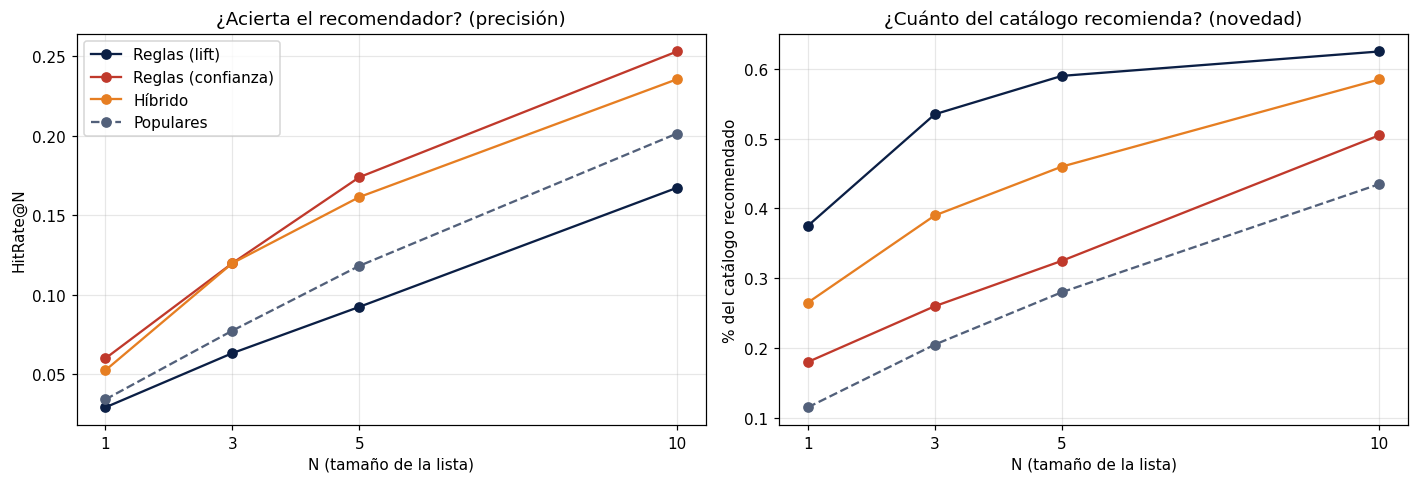

In [36]:
colores = {"Reglas (lift)": AZUL, "Reglas (confianza)": ROJO, "Híbrido": "#e67e22", "Populares": GRIS}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: precisión (HitRate@N)
for nombre, color in colores.items():
    ax[0].plot(resultados["N"], resultados[nombre], marker="o", color=color, label=nombre,
               linestyle="--" if nombre == "Populares" else "-")
ax[0].set_xlabel("N (tamaño de la lista)")
ax[0].set_ylabel("HitRate@N")
ax[0].set_title("¿Acierta el recomendador? (precisión)")
ax[0].set_xticks([1, 3, 5, 10])
ax[0].grid(alpha=0.3)
ax[0].legend()

# Derecha: variedad (cobertura del catálogo)
for nombre, color in colores.items():
    ax[1].plot(coberturas["N"], coberturas[nombre], marker="o", color=color, label=nombre,
               linestyle="--" if nombre == "Populares" else "-")
ax[1].set_xlabel("N (tamaño de la lista)")
ax[1].set_ylabel("% del catálogo recomendado")
ax[1].set_title("¿Cuánto del catálogo recomienda? (novedad)")
ax[1].set_xticks([1, 3, 5, 10])
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.3 Discusión: precisión vs. novedad

Se evaluaron 1.201 usuarios de prueba (todos tienen al menos 2 películas, por el filtro de la sección 3).

**1. Las reglas ordenadas por confianza superan a la línea base.** Aciertan la película oculta en primer lugar en el 6,0 % de los casos, contra 3,4 % de los populares (casi el doble), y con 10 recomendaciones llegan a 25,3 % contra 20,1 %. A diferencia de *Groceries*, donde las reglas apenas igualaban a los más vendidos, aquí los gustos tienen una estructura fuerte (sagas, géneros, épocas) que las reglas logran capturar.

**2. Las reglas ordenadas por lift aciertan menos, pero recomiendan mucho más variado.** Su HitRate@10 es de 16,7 %, por debajo de los populares, pero llegan a recomendar el 62,5 % del catálogo, contra 43,5 % de los populares. Con una sola recomendación la diferencia es aún mayor: 37,5 % del catálogo frente a 11,5 %. El lift sugiere películas específicas del perfil del usuario, que suelen ser menos populares y por eso más difíciles de "adivinar" en esta prueba.

**3. El híbrido logra el mejor equilibrio.** Iguala a la confianza en HitRate@3 (12,0 %), queda cerca con 10 recomendaciones (23,6 %) y recomienda más catálogo que ella (58,5 % contra 50,5 %). Además usa reglas en el 99,2 % de los casos: solo conmuta a populares cuando ninguna regla fuerte se activa.

**El dilema precisión vs. novedad.** La confianza es más precisa porque tiende a recomendar películas populares que el usuario probablemente ya vio, mientras que el lift aporta novedad a costa de precisión. Hay que tener en cuenta que esta evaluación *offline* favorece a lo popular: la película oculta sale de lo que el usuario ya vio, y ahí las populares están sobrerrepresentadas. Una recomendación por lift que no "acierta" puede ser igual de valiosa si le muestra al usuario una película que no conocía; eso solo se puede medir con usuarios reales (por ejemplo, una prueba A/B). Para la plataforma, recomendamos usar el **híbrido** como sistema principal.

## 8. Hallazgos y recomendaciones

### 8.1 Hallazgos principales

1. **Los gustos se concentran en pocas películas.** De 3.533 películas con alguna nota ≥ 4, el 53,8 % le gusta a menos del 1 % de los usuarios, mientras que las 200 más populares concentran el 37,9 % de todas las evaluaciones positivas. Por el principio Apriori, analizar esas 200 (6.004 usuarios) no pierde ninguna regla posible con los umbrales usados.

2. **Las reglas encontradas son sólidas.** Con soporte 0,15 y confianza 0,6 se obtienen 341 reglas, cada una respaldada por al menos 900 usuarios. Las 341 son estadísticamente significativas (test de Fisher con corrección de Holm) y ninguna es redundante. Las más fuertes conectan **sagas** (*El Padrino II ⇒ El Padrino*, confianza 0,87; *Aliens ⇒ Alien*, lift 2,69) y **estilos de una época** (*Raiders + Star Wars V ⇒ Indiana Jones y la Última Cruzada*, lift 2,82, el más alto).

3. **Los usuarios forman comunidades de gusto.** Sin conocer los géneros, el mapa de flujo agrupó solo las películas en comunidades reconocibles: animación familiar, cine criminal de los 90, acción de los 80, clásicos, ciencia ficción de culto y comedias juveniles.

4. **La confianza por sí sola engaña.** *American Beauty* le gusta al 47,5 % de los usuarios, así que casi cualquier regla que termina en ella tiene confianza cercana a 0,5 aunque no haya afinidad (por ejemplo, *Star Trek II ⇒ American Beauty* tiene lift 1,01). El lift es el criterio que distingue una afinidad real de la simple popularidad.

5. **El recomendador por reglas supera a recomendar lo más popular.** Ordenando por confianza acierta la película oculta en primer lugar en el 6,0 % de los casos, contra 3,4 % de los populares, y con 10 recomendaciones llega a 25,3 % contra 20,1 %. Ordenando por lift acierta menos (16,7 % con N = 10), pero recomienda el 62,5 % del catálogo, contra 43,5 % de los populares. El **híbrido** (reglas con lift ≥ 2, ordenadas por confianza) combina ambas virtudes: acierta 23,6 % con N = 10 y recomienda el 58,5 % del catálogo.

6. **El arranque en frío es la principal limitación.** Un usuario que solo valoró películas fuera de las 200 más populares (como *Mulan*) no activa ninguna regla y recibe recomendaciones genéricas.

### 8.2 Recomendaciones para la plataforma

- **Usar el híbrido como fila principal "Porque te gustó…"**, mostrando la película que originó cada sugerencia. Es el sistema más equilibrado: casi tan preciso como la confianza y con mucha más variedad.
- **Agregar una fila "Descubre" ordenada por lift**, para sacar a la luz títulos del catálogo que el usuario probablemente no conoce. Aunque acierta menos en la evaluación offline, es la que más amplía el consumo del catálogo.
- **Armar filas temáticas a partir de las comunidades de gusto** (por ejemplo, *"Más cine criminal de los 90"*), y usar las películas que conectan dos comunidades, como *Terminator* entre acción y ciencia ficción, como puerta de entrada a un género nuevo.
- **Dirigir las campañas de estrenos con consultas dirigidas.** Para *Gladiator*, el público objetivo son quienes valoraron *Matrix*, *Rescatando al soldado Ryan* o *Corazón valiente*, a quienes les gusta con el doble de probabilidad que al usuario promedio.
- **Resolver el arranque en frío fuera de las reglas**: pedir a los usuarios nuevos que elijan 3 películas favoritas al registrarse, o recomendar por género cuando no haya reglas que se activen.

### 8.3 Limitaciones y próximos pasos

- El análisis cubre solo las 200 películas más populares; las películas de nicho necesitan otros métodos (por ejemplo, filtrado colaborativo o recomendación por contenido).
- Pasar las notas a "le gustó / no le gustó" (nota ≥ 4) pierde la intensidad del gusto: un 5 y un 4 cuentan igual.
- Las reglas no consideran el orden en que se vieron las películas; el *timestamp* de `ratings.dat` permitiría estudiar secuencias (qué se ve después de qué).
- La evaluación offline favorece a lo popular. El valor real de las recomendaciones por lift solo se puede medir con usuarios reales, mediante una prueba A/B.
- Los datos son del año 2000; las asociaciones podrían ser distintas en un catálogo actual.

## 9. Exportación de CSV para el dashboard

El dashboard no vuelve a minar reglas: lee los resultados del notebook desde archivos CSV en la carpeta `data/`. Así la app carga rápido y muestra exactamente los mismos resultados que este análisis. Además, como la licencia de MovieLens no permite redistribuir los datos originales, al repositorio solo se suben estos resultados.

| Archivo | Contenido | Módulo del dashboard |
|---|---|---|
| `reglas.csv` | Reglas con soporte ≥ 0,10 y confianza ≥ 0,5, con soporte, confianza, lift, leverage y convicción | Explorador de reglas y dispersión |
| `reglas_recomendador.csv` | Reglas película → película del recomendador (sección 6) | Recomendador, grafo y mapa de flujo |
| `populares.csv` | Las 200 películas con su soporte, número de usuarios y géneros | Resumen de datos y respaldo de populares |
| `hitrate.csv` | HitRate@N, cobertura y % de regla activa de los 4 sistemas | Evaluación |
| `resumen.csv` | Indicadores generales (transacciones, ítems, densidad, umbrales) | Resumen de datos |

Las reglas para el explorador usan umbrales más bajos que los finales (0,15 y 0,6) para que el usuario pueda mover los controles en ambas direcciones.

In [37]:
import os

os.makedirs("data", exist_ok=True)


def a_texto(itemset):
    # Convierte un frozenset en texto plano para el CSV, por ejemplo: "Alien (1979) | Aliens (1986)"
    return " | ".join(sorted(itemset))


# 1) Reglas para el explorador (umbrales más amplios que los finales, para que los controles tengan rango)
reglas_dashboard = association_rules(itemsets_bajos, metric="confidence", min_threshold=0.5)
reglas_csv = pd.DataFrame({
    "antecedente": reglas_dashboard["antecedents"].apply(a_texto),
    "consecuente": reglas_dashboard["consequents"].apply(a_texto),
    "regla": reglas_dashboard["antecedents"].apply(texto_itemset) + " ⇒ " + reglas_dashboard["consequents"].apply(texto_itemset),
    "largo_antecedente": reglas_dashboard["antecedents"].apply(len),
    "soporte": reglas_dashboard["support"],
    "confianza": reglas_dashboard["confidence"],
    "lift": reglas_dashboard["lift"],
    "leverage": reglas_dashboard["leverage"],
    "conviccion": reglas_dashboard["conviction"],
}).sort_values("lift", ascending=False).round(4)
reglas_csv.to_csv("data/reglas.csv", index=False)

# 2) Reglas del recomendador (película → película)
recomendador_csv = pd.DataFrame({
    "antecedente": reglas_rec["antecedents"].apply(a_texto),
    "producto": reglas_rec["producto"],
    "soporte": reglas_rec["support"],
    "confianza": reglas_rec["confidence"],
    "lift": reglas_rec["lift"],
}).round(4)
recomendador_csv.to_csv("data/reglas_recomendador.csv", index=False)

# 3) Películas más populares, con su ranking, número de usuarios y géneros
generos = peliculas.set_index("titulo")["generos"]
orden_popularidad = soporte_top.sort_values(ascending=False)
populares_csv = pd.DataFrame({
    "ranking": range(1, len(orden_popularidad) + 1),
    "pelicula": orden_popularidad.index,
    "soporte": orden_popularidad.values.round(4),
    "usuarios": (orden_popularidad.values * len(gustos_top)).round().astype(int),
})
populares_csv["generos"] = populares_csv["pelicula"].map(generos)
populares_csv.to_csv("data/populares.csv", index=False)

# 4) Evaluación: HitRate@N y cobertura en formato largo (una fila por N y sistema)
hitrate_csv = (resultados.melt(id_vars="N", var_name="sistema", value_name="hitrate")
               .merge(coberturas.melt(id_vars="N", var_name="sistema", value_name="cobertura"), on=["N", "sistema"]))
hitrate_csv["regla_activa"] = hitrate_csv["sistema"].map({n: c / len(casos) for n, c in con_regla.items()})
hitrate_csv.round(4).to_csv("data/hitrate.csv", index=False)

# 5) Indicadores generales
resumen_csv = pd.DataFrame({
    "indicador": ["usuarios_totales", "peliculas_totales", "transacciones", "items", "densidad",
                  "soporte_min", "confianza_min", "reglas_finales", "reglas_recomendador",
                  "lift_minimo_hibrido", "casos_prueba"],
    "valor": [len(gustos), gustos.shape[1], len(gustos_top), gustos_top.shape[1], round(gustos_top.values.mean(), 4),
              SOPORTE_MIN, CONFIANZA_MIN, len(reglas_finales), len(reglas_rec),
              LIFT_MINIMO, len(casos)],
})
resumen_csv.to_csv("data/resumen.csv", index=False)

# Verificación: archivos creados y su tamaño
for archivo in sorted(os.listdir("data")):
    tamaño = os.path.getsize(f"data/{archivo}") / 1024
    filas = len(pd.read_csv(f"data/{archivo}"))
    print(f"{archivo:28s} {filas:>7,} filas   {tamaño:>8,.1f} KB")

hitrate.csv                       16 filas        0.5 KB
populares.csv                    200 filas       11.2 KB
reglas.csv                    10,954 filas    2,953.2 KB
reglas_recomendador.csv        4,802 filas      343.9 KB
resumen.csv                       11 filas        0.2 KB


In [38]:
import shutil

# Comprimimos la carpeta data/ y la descargamos (solo funciona en Colab)
shutil.make_archive("data", "zip", "data")
try:
    from google.colab import files
    files.download("data.zip")
except ImportError:
    print("Archivo data.zip creado en la carpeta del notebook.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>